# Environmental Footprints of Housing
This code calculates environmental footprints of housing under a given set of energy use, energy technology, housing size of different building types, and transport use in relation to location and income.

For the analysis of current housing in NL the following datasets are needed:
- Set of assumptions: CBS microdata output
- Material use per building types
- Material use per solar PV capacity
- Material use per heat pump
- District heat source distribution
- Emission factors per pkm, kg, kWh

In [352]:
# data processing modules
import pandas as pd
import numpy as np

# data visualisation modules
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns

# Display options
pd.options.display.float_format = '{:,.2f}'.format #limits printed decimal points to two
#pd.reset_option('^display.', silent=True) #option to reset the previous display option

In [353]:
def multiply_subcategories(df_detail, df_aggregate):
    """ 
    Multiplies a detailed dataframe with an aggregated dataframe

    Returns a detailed dataframe in which each each row is multiplied with the corresponding row in the aggregated dataframe
    Index level 0 of the detailed dataframe must match the index of the aggregated dataframe.
    
    Args:
        df_detail: multi-indexed dataframe of length a*b and width c
        df_aggregate: dataframe of length a and width c
    
    Returns: 
        pandas.DataFrame: Detailed dataframe of length a*b and width c in which each each row is multiplied with the corresponding row in the aggregated dataframe
        """
    df_new = pd.DataFrame(index=df_detail.index, columns=df_detail.columns)
    for i in df_aggregate.index:
        df_new.update(df_detail.xs(i, axis=0, level=0, drop_level=False).mul(df_aggregate.loc[i], axis=1))
        
    return df_new


In [354]:
def bubblechart(total, per, bubblesize, y_level, category_level, xlabel, ylabel, filename, bubblecolors=['#ffb000', '#fe6100','#dc267f','#785ef0', '#648fff','#808080']): #(use['size'+year+'_w1']*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 1, 'm2 floor area per capita', class_name_long, 'm2_per_cap_class_type'
    #floor area per income level
    use_m2_total_class = total.groupby(level=y_level, sort=False).sum() #m2 total in each group summed by income level
    use_cap_total_class = per.groupby(level=y_level, sort=False).sum() #no. of people in each group summed by income level
    use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group

    #floor area per income level and building type
    use_m2_total_class_type = total.groupby(level=[y_level,category_level], sort=False).sum() #m2 total in each group summed by income level
    use_cap_total_class_type = per.groupby(level=[y_level,category_level], sort=False).sum() #no. of people in each group summed by income level
    use_m2_per_cap_class_type = use_m2_total_class_type / use_cap_total_class_type #m2/cap in each income group

    #preparing the dataframes for plotting
    df = use_m2_per_cap_class
    df2=use_m2_per_cap_class_type.rename('value').to_frame()
    df2['n_hhd'] = bubblesize.groupby(level=[y_level,category_level], sort=False).sum()
    df2 = df2.reset_index()

    #plot
    colors = ['#000000', #construction
                                '#fe6100', #buildings                                              
                                            '#648fff', #roads
                                            '#785ef0', #railways
                                            '#ffb000', #electricity
                                            '#808080', #other civil engineering
                                            '#000000', #construction
                                            ]
    fig = px.bar(df, x=df.values, y=df.index,  
                labels={'x':xlabel, lab:ylabel, 'density_lab':ylabel}, 
                template='simple_white', 
                color_discrete_sequence=colors) 
    fig.update_layout(width=1000, height=500, 
                        #xaxis_tickformat = '.0%',
                        font=dict(size=18),
                        bargap=0.9,
                        legend=dict(
            orientation="h",
            #entrywidth=70,
            yanchor="bottom",
            y=1.02,
            xanchor="left",
            x=-0.25,
        ))

    df2=use_m2_per_cap_class_type.rename('value').to_frame()
    df2['n_hhd'] = bubblesize.groupby(level=[y_level,category_level], sort=False).sum()
    
    count=0
    for i in df2.index.get_level_values(1).unique().to_list():
        df_plot = df2.xs(i, level=1)
        fig.add_trace(go.Scatter(
                y=df_plot.index, 
                x=df_plot['value'],
                mode='markers',
                name=i,
                legendrank=count,
                marker=dict(size=df_plot['n_hhd'],
                            sizemode='area',
                            sizeref=4*max(df2['n_hhd'])/(40.**2),
                            sizemin=4,
                            color=bubblecolors[count],
                            ),
                showlegend=True
            ))
        count=count+1

    fig.write_image('visualisations/'+class_name_short+'/bubblechart_'+filename+year+'.png', scale=3)
    fig.show()

## Foreground System: Calculate and Harmonize Direct Material, Fuel & Electricity Use

### Set of Assumptions
- configure assumptions
- import the CBS file

In [355]:
# Configurations
scenario = 'current'
year = '2019'
classification = 'tenure' #alternative: 'tenure'
if classification == 'income':
    lab = 'inc_lab'
    class_name = 'income level'
    class_name_short = 'income'
    class_name_long = 'equivalised income level'
    class_col = 'inc_decile'
else: #if tenure
    lab = 'tenure_lab'
    class_name = 'tenure'
    class_name_short = 'tenure'
    class_name_long = 'tenure'
    class_col = str('tenure'+year)
material_buildings_source = 'Oorschot-MPG' #alternative 'Oorschot' contains a different grouping (semi-detached and detached together, instead of row and semi-detached)
material_solarpv_source = 'ecoinvent'
material_heatpump_source = 'ecoinvent'
material_pkminfra_source = None
fuel_pkm_source = None
ghg_pkm_source = 'Milieucentraal' #alternative ecoinvent, but not available for NL specifically
ghg_districtheating_source = 'BONSAI' #alternative 'BONSAI' assumes roughly 1.5 the emission intensity of 'Verhagen', 'Herberigs' assumes 1.4 times emission intensity of Verhagen


# File import
if scenario == "current":
    use = pd.read_excel(
        "data_input/output/"+class_name_short+" typology construction density distance privacy "+year+".xlsx",
        #"data_input/output/income typology construction density distance privacy "+year+".xlsx",
        index_col=[0,1,2,3,4],
        header=[0],
    )

    mobility = pd.read_excel(
            "data_input/output/"+class_name_short+" density distance privacy odin "+year+".xlsx",
           #"data_input/output/income density distance privacy odin "+year+".xlsx",
            index_col=[0,1,2],
            header=[0],
        )

    # add transport use and vehicles per household to other variables, assumption: households with similar income, surrounding population density and distance to train station show similar mobility behaviour irrespective of building type or building age
    use_pkm = mobility['dist_carpp_py'] / mobility['n_hhd']#pkm per year per household
    use_pkm.name = 'car_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_vkm = mobility['dist_car_py'] / mobility['n_hhd']#pkm per year per household
    use_vkm.name = 'car_vkm'
    use = use.join(use_vkm, on=[lab,'density_lab', 'distance_train_lab'])


    use_pkm = mobility['dist_transit_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'transit_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_walk_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'walk_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use_pkm = mobility['dist_cycle_py'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'cycle_pkm'
    use = use.join(use_pkm, on=[lab,'density_lab', 'distance_train_lab'])

    use = use.join(mobility['car_hhd'], on=[lab,'density_lab', 'distance_train_lab']) #cars per household

    #weighting the pkm depending on number of adults in household i.e. more pkm allocated to households with more adults, less to households with fewer adults
    use_cap_per_hhd_mean = (use['n_adultmem'+year].groupby(level=[0,3,4], sort=False).sum()/use['n_hhd'].groupby(level=[0,3,4], sort=False).sum()) 
    use_cap_per_hhd_mean.name = 'n_mem_per_hhd_mobility'
    use = use.join(use_cap_per_hhd_mean, on=[lab,'density_lab', 'distance_train_lab'])
    use['mem_weight'] = (use['n_adultmem'+year]/use['n_hhd'])/use['n_mem_per_hhd_mobility']

    for i in ['car_pkm', 'transit_pkm', 'walk_pkm', 'cycle_pkm','car_hhd']:
        use[i] = use[i]*use['mem_weight']

    #change index labels to create more readable graphs
    use = use.rename(index={'detached (vrijstaand)':'detached', 'multiple fam (meergezins)':'multifamily', 'row house (tussenwoning)':'row house', 'semi-detached (2-1 kap) / corner (hoek)':'semi-detached'}, level=1)
    
    
    # output the combined file (including building attributes and mobility behaviour)
    use.to_csv('data_input/output/use.csv')

#### Descriptive statistics: Household characteristics

In [356]:
(use['size'+year+'_w1']*use['n_hhd']) / (use['size'+year+'pp_w1']*use['n_hhdmem'+year]) #use the size per household to stay consistent with total floor space

tenure_lab      typology_lab  const_lab  density_lab  distance_train_lab
owner occupied  detached      pre 1945   very urban   nearest quintile     0.93
                                                      2nd quintile         0.92
                                                      3nd quintile         0.92
                                                      4nd quintile         0.99
                                                      furthest quintile    0.88
                                                                           ... 
priate rental   multifamily   2006-2022  rural        nearest quintile     1.08
                                                      2nd quintile         1.23
                                                      3nd quintile         2.32
                                                      4nd quintile         1.86
                                                      furthest quintile    1.74
Length: 1795, dtype: float64

<AxesSubplot: xlabel='tenure_lab'>

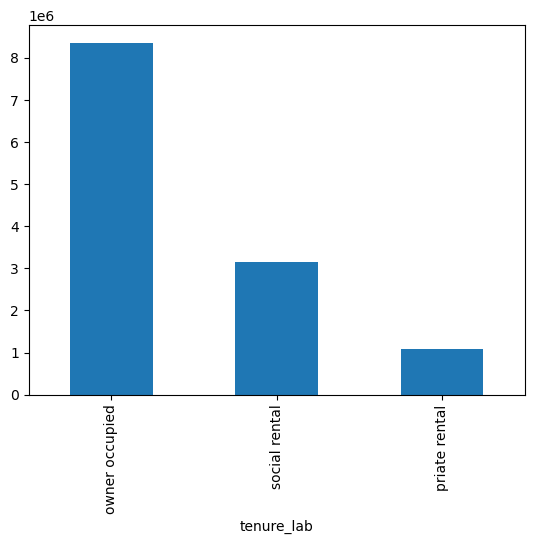

In [357]:
use['n_adultmem'+year].groupby(level=0, sort=False).sum().plot(kind='bar') 

In [358]:
bubblechart(use['n_hhdmem'+year], use['n_hhd'], use['n_hhd'], 0, 1, 'members per household', class_name_long,'cap_per_hhd_class_type')

In [359]:
    df = use['n_hhdmem'+year].groupby(level=[1,2], sort=False).sum().reset_index()
    fig = px.bar(df, y='n_hhdmem'+year, x='typology_lab',color='const_lab', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'n_hhdmem'+year:'Number of residents',
                         'typology_lab':'',
                         'const_lab':''}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Prism) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=650, height=650, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=14),
                      legend=dict(
        traceorder='reversed',
        #orientation="h",
        #entrywidth=70,
        #yanchor="bottom",
        #y=1.02,
        #xanchor="left",
        #x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/'+class_name_short+'/stackedbars_cap_per_type_age'+year+'.png', scale=3)
    fig.show()

In [360]:
    df = use['n_hhdmem'+year].groupby(level=[1,3], sort=False).sum().reset_index()
    fig = px.bar(df, y='n_hhdmem'+year, x='typology_lab',color='density_lab', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'n_hhdmem'+year:'Number of residents',
                         'typology_lab':'',
                         'density_lab':''}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Prism) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=650, height=650, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=14),
                      legend=dict(
        traceorder='reversed',
        #orientation="h",
        #entrywidth=70,
        #yanchor="bottom",
        #y=1.02,
        #xanchor="left",
        #x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/'+class_name_short+'/stackedbars_cap_per_type_urb'+year+'.png', scale=3)
    fig.show()

In [361]:
    df = use['n_hhdmem'+year].groupby(level=[1,0], sort=False).sum().reset_index()
    fig = px.bar(df, y='n_hhdmem'+year, x='typology_lab',color=lab, 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'n_hhdmem'+year:'Number of residents',
                         'typology_lab':'',
                         lab:class_name_short}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Prism) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=650, height=650, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=14),
                      legend=dict(
        traceorder='reversed',
        #orientation="h",
        #entrywidth=70,
        #yanchor="bottom",
        #y=1.02,
        #xanchor="left",
        #x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/'+class_name_short+'/stackedbars_cap_per_type_class'+year+'.png', scale=3)
    fig.show()

### Service inequality visualisations: floor area, electricity, pkm

#### Floor area

In [362]:
bubblechart((use['size'+year+'pp_w1']*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 1, 'm2 floor area per capita', class_name_long, 'm2_per_cappp_class_type')

In [363]:
bubblechart((use['size'+year+'_w1']*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 1, 'm2 floor area per capita', class_name_long, 'm2_per_cap_class_type')

In [364]:
((use['size'+year+'_w1']*use['n_hhd'])/use['n_hhdmem'+year]).sort_values().head(30)

tenure_lab      typology_lab   const_lab  density_lab    distance_train_lab
priate rental   row house      2006-2022  very urban     furthest quintile    32.98
owner occupied  multifamily    1965-1974  very urban     furthest quintile    34.60
social rental   row house      2006-2022  very urban     4nd quintile         34.96
                multifamily    1946-1964  very urban     3nd quintile         36.17
                row house      pre 1945   very urban     4nd quintile         36.39
                detached       2006-2022  low suburban   2nd quintile         37.71
                multifamily    pre 1945   very urban     4nd quintile         38.04
                semi-detached  pre 1945   very urban     4nd quintile         38.82
                               2006-2022  very urban     4nd quintile         38.85
                multifamily    pre 1945   very urban     3nd quintile         38.92
                row house      pre 1945   urban          4nd quintile         39.15


In [365]:
((use['size'+year+'_w1']*use['n_hhd'])/use['n_hhdmem'+year]).sort_values(ascending=False).head(30)

tenure_lab     typology_lab  const_lab  density_lab    distance_train_lab
priate rental  detached      1965-1974  very urban     nearest quintile     672.70
                             1975-1991  very urban     3nd quintile         583.28
                                                       2nd quintile         518.00
                             1992-2005  very urban     2nd quintile         454.23
                                                       3nd quintile         443.62
social rental  detached      1975-1991  very urban     2nd quintile         419.27
                             1965-1974  urban          3nd quintile         415.50
priate rental  detached      1965-1974  very urban     2nd quintile         412.19
social rental  detached      1992-2005  urban          2nd quintile         406.00
priate rental  detached      pre 1945   very urban     4nd quintile         381.16
                             1975-1991  very urban     nearest quintile     366.58
social rental

In [366]:
bubblechart((use['size'+year+'_w1']*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 1, 'm2 floor area per household', class_name_long, 'm2_per_hhd_class_type')

'interpretation: household size (especially adult members) increases with income level (exception when including children: lowest two levels because of single-parents), \nbut without strong correlation with the floor area per capita'

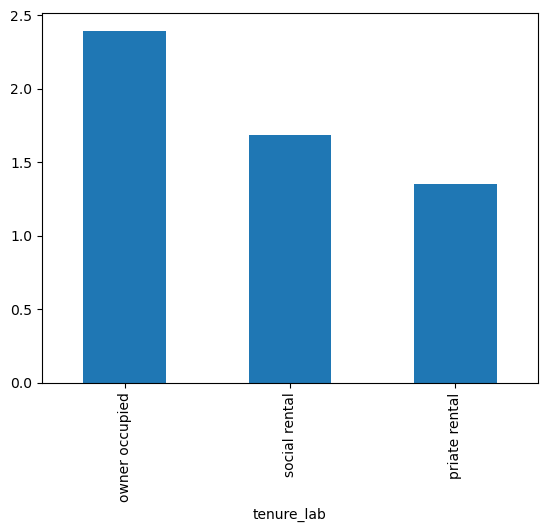

In [367]:
use_cap_total_class = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_hhd_total_class = use['n_hhd'].groupby(level=0, sort=False).sum() #no. of households in each group summed by income level
use_cap_per_hhd_class = use_cap_total_class/use_hhd_total_class 
use_cap_per_hhd_class.plot(kind='bar')
"""interpretation: household size (especially adult members) increases with income level (exception when including children: lowest two levels because of single-parents), 
but without strong correlation with the floor area per capita"""

'interpretation: whether people live in a detached or multi-dwelling building is more indicative of the floor area per capita than their income; the higher floor area among the higher income deciles seems to be related to the type of building people live in rather than affording larger dwellings in the same category of building'

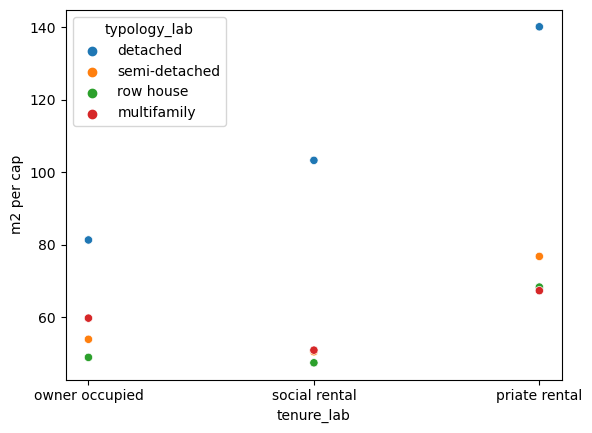

In [368]:
use_m2_total_class = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('m2 per cap').reset_index()
sns.scatterplot(x=lab, y='m2 per cap', data=df_plot, hue='typology_lab')
"""interpretation: whether people live in a detached or multi-dwelling building is more indicative of the floor area per capita than their income; the higher floor area among the higher income deciles seems to be related to the type of building people live in rather than affording larger dwellings in the same category of building"""
#TODO: plot this as bubble plot with size of dot indicating number of households or people in each group

'interpretation: whether people live on the countryside or urban seems to be more indicative for floor area than the income group, although the income group also follows a surprisingly coherent pattern across the urban-rural gradient'

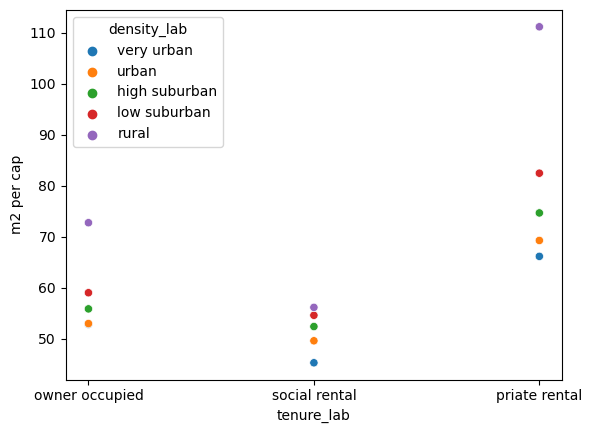

In [369]:
use_m2_total_class = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[0,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[0,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('m2 per cap').reset_index()
sns.scatterplot(x=lab, y='m2 per cap', data=df_plot, hue='density_lab')
"""interpretation: whether people live on the countryside or urban seems to be more indicative for floor area than the income group, although the income group also follows a surprisingly coherent pattern across the urban-rural gradient"""

'building type seems to be more indicative of floor area than the urban-rural gradient, although rural is in each category more floor space intensive than urban buildings of the same type'

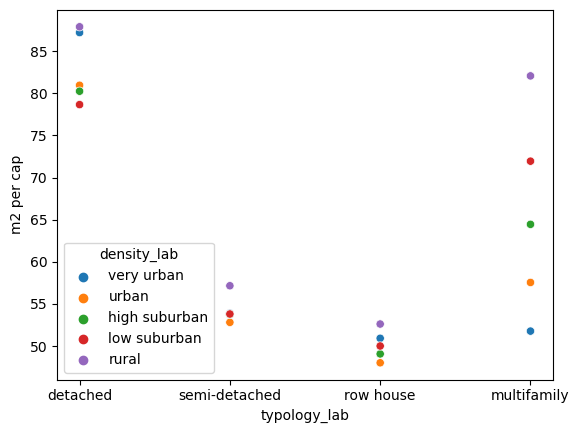

In [370]:
use_m2_total_class = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[1,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[1,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('m2 per cap').reset_index()
sns.scatterplot(x='typology_lab', y='m2 per cap', data=df_plot, hue='density_lab')
"""building type seems to be more indicative of floor area than the urban-rural gradient, although rural is in each category more floor space intensive than urban buildings of the same type"""

'similar to urban-rural'

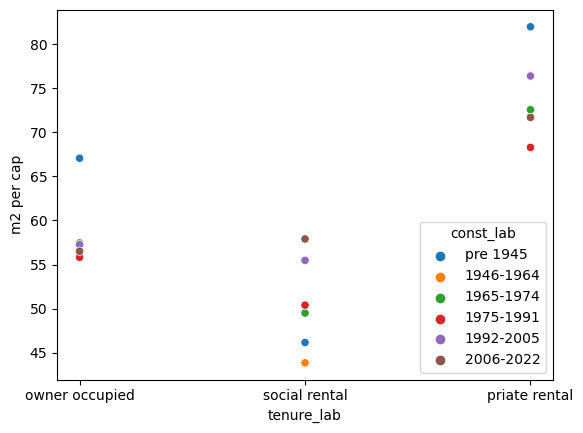

In [371]:
use_m2_total_class = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[0,2], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[0,2], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('m2 per cap').reset_index()
sns.scatterplot(x=lab, y='m2 per cap', data=df_plot, hue='const_lab')
"""similar to urban-rural"""

<AxesSubplot: xlabel='typology_lab', ylabel='m2 per cap'>

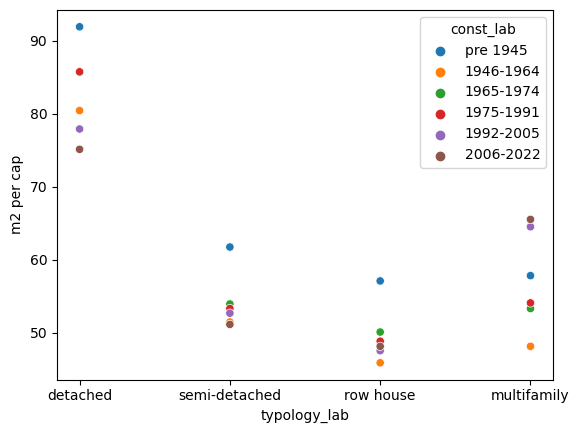

In [372]:
use_m2_total_class = (use['size'+year+'_w1']*use['n_hhd']).groupby(level=[1,2], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[1,2], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('m2 per cap').reset_index()
sns.scatterplot(x='typology_lab', y='m2 per cap', data=df_plot, hue='const_lab')

#### Gas / space heating

In [373]:
bubblechart((use['gas'+year]*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 1, 'GJ gas use per capita per year',class_name_long, 'GJ_per_cap_class_type')

'interpretation: especially the highest income decile has considerably more gas consumption per capita than the vast majority'

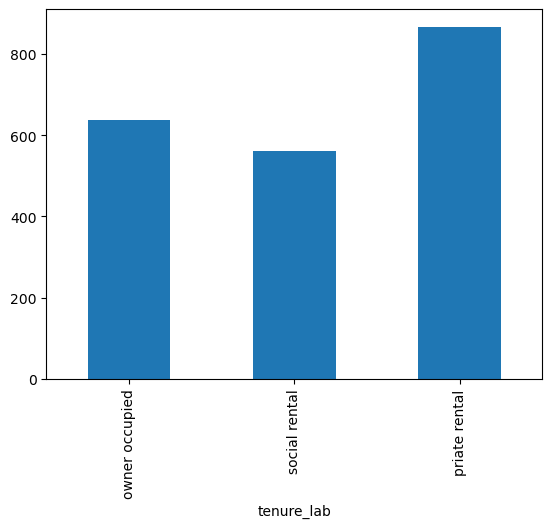

In [374]:
use_m2_total_class = (use['gas'+year]*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more gas consumption per capita than the vast majority"""

In [375]:
bubblechart((use['netelectricity'+year]*use['n_hhd']), use['n_hhdmem'+year], use['n_hhd'], 0, 2, 'kWh electricity use per capita per year',class_name_long, 'kWh_per_cap_class_age')


In [376]:
((use['netelectricity'+year]*use['n_hhd'])/use['n_hhdmem'+year]).sort_values(ascending=False).head(30)

tenure_lab     typology_lab  const_lab  density_lab    distance_train_lab
social rental  detached      2006-2022  urban          nearest quintile     7,291.81
                             1965-1974  rural          nearest quintile     6,780.64
priate rental  detached      1965-1974  very urban     nearest quintile     6,382.11
social rental  detached      1975-1991  urban          furthest quintile    5,405.36
priate rental  detached      1992-2005  very urban     4nd quintile         5,255.86
                             1975-1991  very urban     2nd quintile         5,232.44
                             1992-2005  very urban     2nd quintile         4,862.43
                                                       3nd quintile         4,852.35
                             1975-1991  very urban     3nd quintile         4,514.72
                             1965-1974  very urban     2nd quintile         4,399.95
social rental  detached      1992-2005  urban          2nd quintile         

In [377]:
((use['netelectricity'+year]*use['n_hhd'])/use['n_hhdmem'+year]).sort_values(ascending=True).head(30)

tenure_lab      typology_lab   const_lab  density_lab    distance_train_lab
owner occupied  semi-detached  2006-2022  rural          nearest quintile     765.48
                row house      2006-2022  rural          nearest quintile     824.36
priate rental   row house      2006-2022  very urban     furthest quintile    845.64
                                          urban          3nd quintile         845.96
                                          high suburban  4nd quintile         857.52
social rental   row house      2006-2022  very urban     3nd quintile         859.40
priate rental   semi-detached  2006-2022  urban          3nd quintile         860.23
owner occupied  semi-detached  2006-2022  low suburban   nearest quintile     870.01
                                          rural          2nd quintile         873.09
                                          low suburban   2nd quintile         876.31
social rental   row house      2006-2022  very urban     nearest quintile 

#### Mobility

In [378]:
bubblechart((use['car_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 3, 'pkm car use per capita per day',class_name_long, 'pkmcar_per_cap_class_urb')

In [379]:
((use['car_pkm']*use['n_hhd']/365)/use['n_hhdmem'+year]).sort_values(ascending=False).head(60)

tenure_lab     typology_lab   const_lab  density_lab  distance_train_lab
priate rental  multifamily    2006-2022  rural        4nd quintile         88.78
                              1965-1974  rural        4nd quintile         86.61
                              1992-2005  rural        4nd quintile         86.12
                              1975-1991  rural        4nd quintile         85.13
               row house      pre 1945   rural        4nd quintile         84.33
               multifamily    pre 1945   rural        4nd quintile         82.69
               semi-detached  pre 1945   rural        4nd quintile         82.14
                              1946-1964  rural        4nd quintile         81.61
               detached       1946-1964  rural        4nd quintile         80.36
                              pre 1945   rural        4nd quintile         79.50
                              1965-1974  rural        4nd quintile         79.49
               multifamily    1946-1

In [380]:
((use['car_hhd']*use['n_hhd']/365)/use['n_hhdmem'+year]).sort_values(ascending=True).head(30)

tenure_lab     typology_lab   const_lab  density_lab  distance_train_lab
social rental  detached       1965-1974  rural        nearest quintile     0.01
               row house      2006-2022  rural        nearest quintile     0.02
                              1965-1974  rural        nearest quintile     0.02
               multifamily    1946-1964  rural        nearest quintile     0.02
               row house      1946-1964  rural        nearest quintile     0.02
               semi-detached  1965-1974  rural        nearest quintile     0.02
                              2006-2022  rural        nearest quintile     0.02
               row house      1975-1991  rural        nearest quintile     0.02
priate rental  semi-detached  2006-2022  rural        2nd quintile         0.02
social rental  semi-detached  1946-1964  rural        nearest quintile     0.02
priate rental  row house      1946-1964  rural        2nd quintile         0.02
social rental  row house      1992-2005  rural 

In [381]:
bubblechart((use['transit_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 4, 'pkm transit use per capita per day',class_name_long, 'pkmtrain_per_cap_class_dist')

In [382]:
bubblechart((use['cycle_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 3, 'km bicycle use per capita per day',class_name_long, 'pkmbike_per_cap_class_urb')

In [383]:
bubblechart((use['walk_pkm']*use['n_hhd']/365), use['n_hhdmem'+year], use['n_hhd'], 0, 4, 'km walking per capita per day',class_name_long, 'pkmwalk_per_cap_class_dist')

In [384]:
bubblechart((use['distance_depstore'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 3, 'distance to department store',class_name_long, 'distance_to_departmentstore_class_urb')

In [385]:
bubblechart((use['distance_supermarket'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 3, 'distance to supermarket',class_name_long, 'distance_to_supermarket_class_urb')

In [386]:
bubblechart((use['distance_middleschool'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 0, 3, 'distance to middleschool',class_name_long, 'distance_to_middleschool_class_urb')

In [387]:
bubblechart((use['distance_depstore'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 3, 0, 'distance to department store [m]','urbanity', 'distance_to_departmentstore_urb_class', bubblecolors=px.colors.sequential.Plasma_r)

In [388]:
bubblechart((use['distance_supermarket'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 3, 0, 'distance to supermarket [m]','urbanity', 'distance_to_supermarket_urb_class', bubblecolors=px.colors.sequential.Plasma_r)

In [389]:
bubblechart((use['distance_middleschool'+year]*use['n_hhd']), use['n_hhd'], use['n_hhd'], 3, 0, 'distance to middleschool [m]','urbanity', 'distance_to_middleschool_urb_class', bubblecolors=px.colors.sequential.Plasma_r)

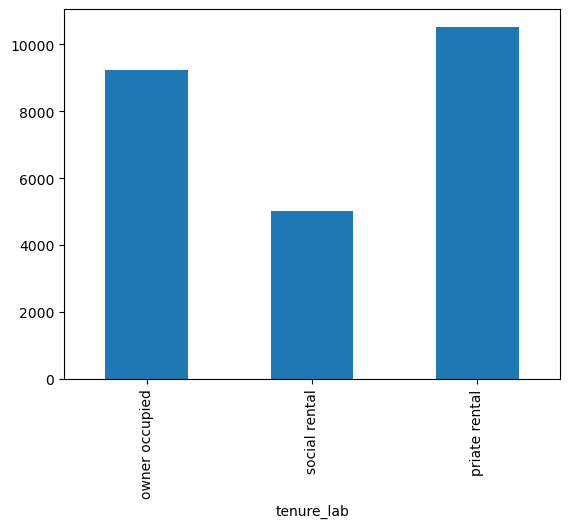

In [390]:
#floor area per income level
use_m2_total_class = (use['car_pkm']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and urbanisation type
use_m2_total_class_type = (use['car_pkm']*use['n_hhd']).groupby(level=[0,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class_type = use['n_hhdmem'+year].groupby(level=[0,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class_type = use_m2_total_class_type / use_cap_total_class_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_class
df2=use_m2_per_cap_class_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,3], sort=False).sum()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'pkm car travel per capita', lab:class_name_long}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))



for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))

fig.write_image('visualisations/'+class_name_short+'/bubblechart_carpkm_per_cap_class_urb'+year+'.png', scale=3)
fig.show()

'population density seems to be more indicative of car travel than the building type, although detached buildings are in each category more car travel intensive than multi-dwelling buildings of the same location'

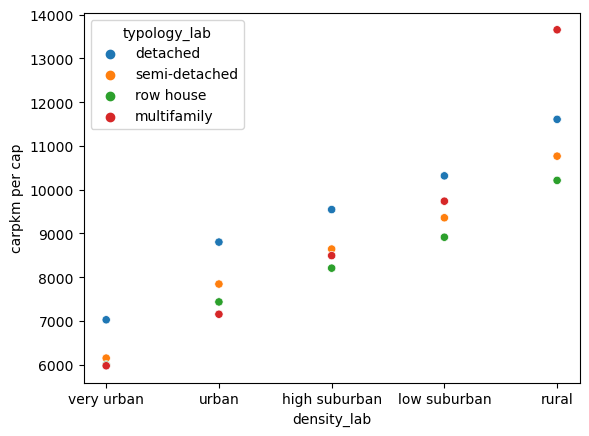

In [391]:
use_m2_total_class = (use['car_pkm']*use['n_hhd']).groupby(level=[1,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[1,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('carpkm per cap').reset_index()
sns.scatterplot(x='density_lab', y='carpkm per cap', data=df_plot, hue='typology_lab')
"""population density seems to be more indicative of car travel than the building type, although detached buildings are in each category more car travel intensive than multi-dwelling buildings of the same location"""

'the distance to the train station especially matters for car travel in rural and suburban areas, so low-density areas that are close to a train station have even lower car travel than urban areas that are close to such a station, whereas urban areas that are far from a train station still have low car travel'

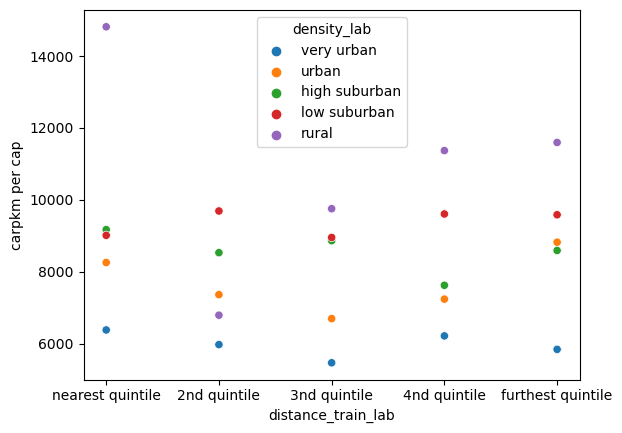

In [392]:
use_m2_total_class = (use['car_pkm']*use['n_hhd']).groupby(level=[3,4], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=[3,4], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class
df_plot = use_m2_per_cap_class.rename('carpkm per cap').reset_index()
sns.scatterplot(x='distance_train_lab', y='carpkm per cap', data=df_plot, hue='density_lab')
"""the distance to the train station especially matters for car travel in rural and suburban areas, so low-density areas that are close to a train station have even lower car travel than urban areas that are close to such a station, whereas urban areas that are far from a train station still have low car travel"""

### Building Construction
- translate floor space to BONSAI material categories
- include material use for maintenance
- normalise impact to annual using building lifetime

In [393]:
# Loading the material intensities per floor area
if material_buildings_source == "Oorschot-MPG": #kg/m2
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023MetabolicMPG.xlsx",
        sheet_name="Building_MI",
        index_col=[0, 1],
        header=[0, 1], skiprows=3
    ).drop("2018-2050", axis=0, level=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.names = ["BONSAI", "Material"]
    mi_buildings.fillna(0, inplace=True)
elif material_buildings_source == "Oorschot": #kg/m2
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="mi_pre2018",
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.name = "Material"

    #converting the material intensities to BONSAI material categories
    mi_buildings_insulation_share = pd.read_excel(
            "data_input/MI_Buildings_Oorschot2023.xlsx",
            sheet_name="Share_of_insulation_materials",
            index_col=[0, 1],
            header=[0],
            skipfooter=3,
        ).drop("Unnamed: 8", axis=1)
    for i in mi_buildings_insulation_share.columns:
        mi_buildings[i] = (
            mi_buildings["Insulation"] * mi_buildings_insulation_share[i].iloc[0]
            )

    mi_buildings = (
            mi_buildings
            .T.groupby(level=0)
            .sum()
            .T.sort_index()
            .replace(0, np.nan)
            .dropna(how="all", axis=1)
            .drop("Insulation", axis=1)
        )
    # matching material names
    replacement_map = {'Bitumen':'Bitumen', #soon
                        'Brick':'Ceramics', #BRIK,
                        'Clay brick':'Ceramics', #BRIK
                        'Ceramics':'Ceramics', #BRIK (bricks, tiles, construction products)
                        'Sand-lime brick':'Ceramics', #BRIK
                        'Sand':'Sand', #SDCL
                        'Concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'Mortal':'Mortar', #CMNT
                        'Gypsum':'Mortar', #CMNT (plaster of gypsum)
                        'Aluminum':'Aluminium', #ALUM
                        'Copper':'Copper', #COPP
                        'Other metals':'Other metals', #ONFM
                        'Electronics':'Electronics', #ELMA
                        'Glass':'Glass', #GLAS 
                        'Glass wool':'Glass', #GLAS (includes explicitely glass wool)
                        'Stone wool':'Mineral wool', #ONMM (includes explicitely mineral wool)
                        'Iron & steel':'Steel', #STEL or FABM
                        'Steel':'Steel', #STEL or FABM
                        'Other biobased materials':'Wood and straw', #WOOD
                        'Wood':'Wood and straw', #WOOD
                        'Other construction materials':'Other construction material', #ONMM, could also be STON, SDCL or CMNT
                        'Other':'Adhesives and paint', #could be CHEM, PLAS, PAPE, ELMA
                        'Paper':'Paper', #PAPE 
                        'Expanded polystyrene':'Plastic', #RUBP 
                        'Extruded polystyrene':'Plastic', #RUBP
                        'Plastic':'Plastic', #RUBP
                        'Plastics':'Plastic', #RUBP
                        'Polyurethanes':'Plastic', #RUBP
                        'Adhesives & paint':'Adhesives and paint', #CHEM (other chemical products, for glues) or PLAS (basic plastics) 
                        'Stone':'Stone', #STON
                        }

    mi_buildings = mi_buildings.stack().reset_index()
    mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
    mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Cohort', 'Material_group']).sum().unstack().droplevel(0, axis=1)

    #selecting only residential buildings
    mi_buildings.drop(['industry', 'office', 'services', 'shop'], axis=0, level=0, inplace=True)




In [394]:
# visualisation of the assumed material intensities
""" the trend shows a shift from wood to brick and concrete"""
m_plot = mi_buildings.copy()
m_plot = m_plot.rename(index={'pre 1945':'1000-1945'})
if material_buildings_source == "Oorschot-MPG":
    m_plot = m_plot.groupby(axis=1, level=0).sum()
m_plot.index = [str(i) + ' ' + str(j) for i, j in m_plot.index]
m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'material', 'value']
fig = px.bar(m_plot, x='value', y='building', color='material', labels={'value':'material intensity per floor area [kg/m2]'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=1100, height=500, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/'+class_name_short+'/mi_buildings'+material_buildings_source+'_grouped.svg')
fig.show()

In [395]:
#calculating the material contained in an average dwelling per category
mi_buildings.index = mi_buildings.index.rename(['typology_lab', 'const_lab']) # kg/m2 ufa
use_m2 = use['size'+year+'_w1'].reorder_levels(['typology_lab', 'const_lab', lab, "density_lab", "distance_train_lab"]) #m2 ufa / dwelling
use_m2 = pd.concat([use_m2] * len(mi_buildings.columns), axis=1)
use_m2.columns = mi_buildings.columns
material_buildings = use_m2.multiply(mi_buildings.reindex(use_m2.index), level=[0,1]) #kg / dwelling

In [396]:
material_buildings #kg / dwelling

BONSAI                                                                          M_ALUM  \
Material                                                             Aluminium (kg/m2)   
typology_lab const_lab tenure_lab     density_lab distance_train_lab                     
detached     pre 1945  owner occupied very urban  nearest quintile               21.69   
                                                  2nd quintile                   19.91   
                                                  3nd quintile                   19.91   
                                                  4nd quintile                   24.40   
                                                  furthest quintile              18.31   
...                                                                                ...   
multifamily  2006-2022 priate rental  rural       nearest quintile               69.37   
                                                  2nd quintile                   81.62   
                                                  3nd quintile                   74.92   
                                                  4nd quintile                   76.45   
                                                  furthest quintile              80.48   

BONSAI                                                                         M_BRIK  \
Material                                                             Baksteen (kg/m2)   
typology_lab const_lab tenure_lab     density_lab distance_train_lab                    
detached     pre 1945  owner occupied very urban  nearest quintile          56,044.64   
                                                  2nd quintile              51,427.51   
                                                  3nd quintile              51,445.07   
                                                  4nd quintile              63,044.52   
                                                  furthest quintile         47,291.79   
...                                                                               ...   
multifamily  2006-2022 priate rental  rural       nearest quintile           4,838.38   
                                                  2nd quintile               5,692.34   
                                                  3nd quintile               5,225.19   
                                                  4nd quintile               5,331.76   
                                                  furthest quintile          5,613.28   

BONSAI                                                               M_CMNT + M_SDCL  \
Material                                                               Beton (kg/m2)   
typology_lab const_lab tenure_lab     density_lab distance_train_lab                   
detached     pre 1945  owner occupied very urban  nearest quintile        265,947.38   
                                                  2nd quintile            244,037.81   
                                                  3nd quintile            244,121.17   
                                                  4nd quintile            299,163.76   
                                                  furthest quintile       224,412.67   
...                                                                              ...   
multifamily  2006-2022 priate rental  rural       nearest quintile        135,381.09   
                                                  2nd quintile            159,275.57   
                                                  3nd quintile            146,204.37   
                                                  4nd quintile            149,186.31   
                                                  furthest quintile       157,063.25   

BONSAI                                                                        M_BITU  \
Material                                                             Bitumen (kg/m2)   
typology_lab const_lab tenure_lab     density_lab distance_train_lab               

#### Environmental Footprint

In [397]:
# File import
mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9) # kg CO2eq. per kg material

#selecting relevant product codes
prod_codes = material_buildings.columns.levels[0].to_list()
prod_codes.append('M_CMNT')
mult_bonsai = mult_bonsai[mult_bonsai.index.get_level_values(0).isin(prod_codes)] 
mult_bonsai = mult_bonsai.droplevel([1,2,3])
mult_bonsai = mult_bonsai[['NL']] #select only NL market

#calculating environmental impacts of composite material concrete
concrete_cement_pc = 0.35 #based on M20 and M25 concrete grade
mult_bonsai.loc['M_CMNT + M_SDCL'] = mult_bonsai.loc[['M_CMNT']].squeeze()*concrete_cement_pc + mult_bonsai.loc[['M_SDCL']].squeeze()*(1-concrete_cement_pc)

mult_bonsai # kg CO2eq. per kg material

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_23855/1297572943.py:2: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



,NL
Exio prod code,
M_STON,0.00
M_SDCL,0.00
M_WOOD,0.89
M_PAPE,2.43
M_BITU,1.79
M_CHEM,1.06
M_RUBP,3.79
M_GLAS,1.29
M_BRIK,0.18


In [398]:
# calculating embodied GHG emissions of materials in buildings
material_buildings_grouped = material_buildings.groupby(axis=1, level=0).sum() #kg/dwelling
ghg_material_buildings = material_buildings_grouped.multiply(mult_bonsai.iloc[:,0], axis=1).dropna(axis=1, how='all') #kg CO2eq. / dwelling

ghg_material_buildings #kg CO2eq/dwelling

M_ALUM  \
typology_lab const_lab tenure_lab     density_lab distance_train_lab           
detached     pre 1945  owner occupied very urban  nearest quintile    134.80   
                                                  2nd quintile        123.70   
                                                  3nd quintile        123.74   
                                                  4nd quintile        151.64   
                                                  furthest quintile   113.75   
...                                                                      ...   
multifamily  2006-2022 priate rental  rural       nearest quintile    431.05   
                                                  2nd quintile        507.13   
                                                  3nd quintile        465.51   
                                                  4nd quintile        475.01   
                                                  furthest quintile   500.09   

                                                                      M_BITU  \
typology_lab const_lab tenure_lab     density_lab distance_train_lab           
detached     pre 1945  owner occupied very urban  nearest quintile      0.00   
                                                  2nd quintile          0.00   
                                                  3nd quintile          0.00   
                                                  4nd quintile          0.00   
                                                  furthest quintile     0.00   
...                                                                      ...   
multifamily  2006-2022 priate rental  rural       nearest quintile    130.76   
                                                  2nd quintile        153.84   
                                                  3nd quintile        141.22   
                                                  4nd quintile        144.10   
                                                  furthest quintile   151.71   

                                                                        M_BRIK  \
typology_lab const_lab tenure_lab     density_lab distance_train_lab             
detached     pre 1945  owner occupied very urban  nearest quintile   21,720.20   
                                                  2nd quintile       19,930.82   
                                                  3nd quintile       19,937.63   
                                                  4nd quintile       24,433.02   
                                                  furthest quintile  18,328.02   
...                                                                        ...   
multifamily  2006-2022 priate rental  rural       nearest quintile    6,193.21   
                                                  2nd quintile        7,286.30   
                                                  3nd quintile        6,688.34   
                                                  4nd quintile        6,824.75   
                                                  furthest quintile   7,185.09   

                                                                      M_CHEM  \
typology_lab const_lab tenure_lab     density_lab distance_train_lab           
detached     pre 1945  owner occupied very urban  nearest quintile    311.45   
                                                  2nd quintile        285.79   
                                                  3nd quintile        285.89   
                                                  4nd quintile        350.35   
                                                  furthest quintile   262.81   
...                                                                      ...   
multifamily  2006-2022 priate rental  rural       nearest quintile    521.57   
                                                  2nd quintile        613.63   
                                                  3nd quintile        563.27   
                                         

In [399]:
ghg_material_buildings.sum(1) #total GHG emission per dwelling

typology_lab  const_lab  tenure_lab      density_lab  distance_train_lab
detached      pre 1945   owner occupied  very urban   nearest quintile     165,379.94
                                                      2nd quintile         151,755.43
                                                      3nd quintile         151,807.27
                                                      4nd quintile         186,035.62
                                                      furthest quintile    139,551.50
                                                                              ...    
multifamily   2006-2022  priate rental   rural        nearest quintile      64,402.78
                                                      2nd quintile          75,769.73
                                                      3nd quintile          69,551.57
                                                      4nd quintile          70,970.12
                                                      furthest quin

### Building Use Phase
- translate district heating to BONSAI fuel categories
- translate solar PV and heat pumps to BONSAI material categories
- harmonise labels for electricity and gas use with BONSAI categories

#### Electricity

In [400]:
# File import
mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9).droplevel([1,2,3]) # tonne CO2eq. per TJ electricity
mult_bonsai = mult_bonsai['NL'] #select only NL market

electricity_buildinguse = use['netelectricity'+year] #kWh per household per year
electricity_buildinguse = electricity_buildinguse * 3.6 #MJ per household per year
electricity_buildinguse = electricity_buildinguse /1e6 #TJ per household per year
ghg_electricity_buildinguse = electricity_buildinguse * mult_bonsai.loc['M_electricity'] * 1000 #kg CO2eq. per household per year

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_23855/1083587744.py:2: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



In [401]:
ghg_electricity_buildinguse #annual GHG emission per household

tenure_lab      typology_lab  const_lab  density_lab  distance_train_lab
owner occupied  detached      pre 1945   very urban   nearest quintile     1,673.53
                                                      2nd quintile         1,575.31
                                                      3nd quintile         1,626.52
                                                      4nd quintile         1,802.31
                                                      furthest quintile    1,660.03
                                                                             ...   
priate rental   multifamily   2006-2022  rural        nearest quintile       877.04
                                                      2nd quintile           933.09
                                                      3nd quintile           938.52
                                                      4nd quintile           886.55
                                                      furthest quintile      949.79
Nam

#### Gas

In [402]:
#M_GASE upstream emissions of natural gas per tonne
#EF_GASE combustion of natural gas per TJ
gas_buildinguse = use['gas'+year] #m3 per household per year
gas_buildinguse_tonne = gas_buildinguse * 0.735 #kg per household per year
ghg_gas_buildinguse_footprint = gas_buildinguse_tonne * mult_bonsai.loc['M_GASE'] #kg CO2eq. per household per year
gas_buildinguse_GJ = gas_buildinguse * 0.0316 #GJ per household per year
ghg_gas_buildinguse_direct = gas_buildinguse_GJ * mult_bonsai.loc['EF_GASE'] #kg CO2eq. per household per year
ghg_gas_buildinguse = ghg_gas_buildinguse_footprint + ghg_gas_buildinguse_direct

In [403]:
ghg_gas_buildinguse #annual GHG emission per household

tenure_lab      typology_lab  const_lab  density_lab  distance_train_lab
owner occupied  detached      pre 1945   very urban   nearest quintile     5,365.19
                                                      2nd quintile         5,038.85
                                                      3nd quintile         5,180.36
                                                      4nd quintile         5,801.54
                                                      furthest quintile    4,631.30
                                                                             ...   
priate rental   multifamily   2006-2022  rural        nearest quintile     1,230.44
                                                      2nd quintile         1,664.70
                                                      3nd quintile         1,578.97
                                                      4nd quintile         1,482.77
                                                      furthest quintile    1,526.92
Nam

#### Heat pump

In [404]:
heatpump_buildings = use['n_heatpump'+year]/use['n_hhd'] #mean number of heatpumps per household
ghg_heatpump_buildings = heatpump_buildings * 386 #kg CO2e per household with heat pump according to Verhagen et al.

In [405]:
ghg_heatpump_buildings #total GHG emission per household

tenure_lab      typology_lab  const_lab  density_lab  distance_train_lab
owner occupied  detached      pre 1945   very urban   nearest quintile       2.49
                                                      2nd quintile           1.37
                                                      3nd quintile            NaN
                                                      4nd quintile            NaN
                                                      furthest quintile       NaN
                                                                            ...  
priate rental   multifamily   2006-2022  rural        nearest quintile     118.77
                                                      2nd quintile            NaN
                                                      3nd quintile            NaN
                                                      4nd quintile          20.27
                                                      furthest quintile     20.66
Length: 1795, dtype: floa

#### District heating

In [406]:
#File import
energy_districtheating = use['n_cityheating'+year]*use['warmteschatting_SW'] / use['n_hhd'] #GJ heat delivered per household per year
energy_districtheating = energy_districtheating * 1.32 #GJ generated pre-distribution, assuming 24% heat loss in high-temperature district heating networks cf. Lund et al. (2014). 4th Generation district heating (4GDH): Integrating smart thermal grids into future sustainable energy systems. Energy, 68, 1–11. https://doi.org/10.1016/j.energy.2014.02.089

if ghg_districtheating_source == 'Verhagen': 
    district_heating = pd.read_excel(
        "data_input/District-Heating-Dataset.xlsx",
        sheet_name = "National average",
        header=[0],
    )
    district_heating.set_index('Heat_Source', inplace=True)

    energy_districtheating_dict = {}
    for i in district_heating.index:
        energy_districtheating_dict[i] = energy_districtheating * district_heating.loc[i, 'Share'] *  district_heating.loc[i, 'kg CO2 per GJ'] #kg CO2e of GJ
    ghg_heat_districtheating = sum(energy_districtheating_dict.values())
elif ghg_districtheating_source == 'BONSAI': #alternative 'BONSAI' assumes rougly 1.5 times the emission intensity of Verhagen
    ghg_heat_districtheating = energy_districtheating/1.32 * mult_bonsai['M_heat_HOUS'] #kg CO2eq. per household per year
else: #'Herberigs' assumes 1.4 times emission intensity of Verhagen
    ghg_heat_districtheating = energy_districtheating * 38.43 #kg CO2eq. per household per year, source Herberigs 2025 https://co2emissiefactoren.nl/factoren/2025/12/48/warmtelevering-gemiddelde-warmtenetten/ 

ghg_heat_districtheating

tenure_lab      typology_lab  const_lab  density_lab  distance_train_lab
owner occupied  detached      pre 1945   very urban   nearest quintile      NaN
                                                      2nd quintile          NaN
                                                      3nd quintile          NaN
                                                      4nd quintile          NaN
                                                      furthest quintile     NaN
                                                                           ... 
priate rental   multifamily   2006-2022  rural        nearest quintile      NaN
                                                      2nd quintile          NaN
                                                      3nd quintile          NaN
                                                      4nd quintile         1.99
                                                      furthest quintile     NaN
Length: 1795, dtype: float64

#### Electricity generation technology

In [407]:
capacity_photovoltaic = use['solarcapacity'+year] #kWp PV per household (including households with and without) 
ghg_material_photovoltaic = capacity_photovoltaic/3 * 6313 #kg CO2eq. per household based on ecoinvent

In [408]:
(use['solarcapacity'+year]*use['n_hhd']/(use['n_solar'+year].fillna(2.5)))/ 3 #kWp per household with 

tenure_lab      typology_lab  const_lab  density_lab  distance_train_lab
owner occupied  detached      pre 1945   very urban   nearest quintile     1.16
                                                      2nd quintile         1.15
                                                      3nd quintile         1.20
                                                      4nd quintile         1.06
                                                      furthest quintile    1.38
                                                                           ... 
priate rental   multifamily   2006-2022  rural        nearest quintile     1.76
                                                      2nd quintile         0.81
                                                      3nd quintile         4.48
                                                      4nd quintile         0.73
                                                      furthest quintile    0.94
Length: 1795, dtype: float64

### Mobility
- add pkm and cars to use data
- translate pkm to BONSAI fuel categories
- translate pkm to infrastructure demand to BONSAI material categories
- normalise cars to annual cars using car lifetime
- harmonise labels for cars with BONSAI categories

In [409]:
if ghg_pkm_source == 'ecoinvent':
    ghg_car_mobilityuse = use['car_pkm']*0.36599 #kg CO2eq (including use phase, infrastructure and vehicle production); Ecoinvent (market for transport, passenger car, Europe (RER)); CMLv4.8 2016
    ghg_transit_mobilityuse = (use['transit_pkm']*0.7)*0.044621 + (use['transit_pkm']*0.3)*0.11334 #kg CO2eq (including use phase, infrastructure, and vehicle production); Ecoinvent (transport, passenger, train (Italy) and transport, regular bus (Switzerland)); CMLv4.8 2016
    ghg_cycle_mobilityuse = use['cycle_pkm']*0.0011864 #kg CO2eq (including infrastructure and vehicle produciton); Ecoinvent (transport, passenter, bicycle, Switzerland); CMLv4.8 2016
elif ghg_pkm_source == 'Milieucentraal':
    ghg_car_mobilityuse = use['car_vkm']*0.193 #kg CO2eq (including use phase, infrastructure and vehicle production); source: Milieucentraal 2022 https://co2emissiefactoren.nl/factoren/2024/38/147/personenvervoer-auto-gemiddelde-auto-brandstofsoort-onbekend/
    ghg_transit_mobilityuse = use['transit_pkm']*0.020 #kg CO2eq (including use phase, infrastructure, and vehicle production); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 
    ghg_cycle_mobilityuse = use['cycle_pkm']*0.0008 #kg CO2eq (including infrastructure and vehicle produciton); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 
elif ghg_pkm_source == 'Milieucentraal - e-car':
    ghg_car_mobilityuse = use['car_vkm']*0.067 #kg CO2eq (including use phase, infrastructure and vehicle production); source: Milieucentraal 2022 https://co2emissiefactoren.nl/factoren/2024/38/147/personenvervoer-auto-gemiddelde-auto-brandstofsoort-onbekend/
    ghg_transit_mobilityuse = use['transit_pkm']*0.020 #kg CO2eq (including use phase, infrastructure, and vehicle production); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 
    ghg_cycle_mobilityuse = use['cycle_pkm']*0.0008 #kg CO2eq (including infrastructure and vehicle produciton); source: STREAM 2022 https://co2emissiefactoren.nl/factoren/2024/53/177/personenvervoer-openbaar-vervoer-ov-algemeen-trein-bus-metro-tram/ 

## Background System: Environmental Footprints

## GHG summary

In [410]:
#source for lifetimes: https://www.oecd-ilibrary.org/docserver/d07136f0-en.pdf?expires=1729253351&id=id&accname=guest&checksum=36E59B772FE676213DBDE7CA1CA5B3D3 
lifetime_building = 80 #years
lifetime_photovoltaic = 30 #years
lifetime_heatpump = 20 #years
#lifetime_car = 10 #years

ghg_annual = pd.concat([
    (ghg_material_buildings.sum(1)/lifetime_building).reorder_levels([2,0,1,3,4]).rename('ghg_material_buildings'), 
    (ghg_heatpump_buildings/lifetime_heatpump).rename('ghg_material_heatpump'), 
    ghg_heat_districtheating.rename('ghg_heat_districtheating'),
    ghg_gas_buildinguse.rename('ghg_gas_buildinguse'), 
    ghg_electricity_buildinguse.rename('ghg_electricity_buildinguse'), 
    (ghg_material_photovoltaic/lifetime_photovoltaic).rename('ghg_material_photovoltaic'),
    ghg_car_mobilityuse.rename('ghg_car_mobilityuse'), 
    #(ghg_car_vehicle/lifetime_car).rename('ghg_car_vehicle'),
    ghg_transit_mobilityuse.rename('ghg_transit_mobilityuse'), 
    ghg_cycle_mobilityuse.rename('ghg_cycle_mobilityuse'), 
    ], axis=1)

In [411]:
ghg_annual.sum(0)

ghg_material_buildings        2,200,009.66
ghg_material_heatpump               414.58
ghg_heat_districtheating         23,172.01
ghg_gas_buildinguse           4,858,150.32
ghg_electricity_buildinguse   2,092,195.15
ghg_material_photovoltaic        45,081.87
ghg_car_mobilityuse           8,322,015.09
ghg_transit_mobilityuse         146,176.53
ghg_cycle_mobilityuse             3,457.71
dtype: float64

In [412]:
ghg_annual_per_cap = ghg_annual.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)
ghg_annual_per_cap.to_csv('data_processed/ghg_annual_per_cap.csv')

In [413]:
    df = ghg_annual.multiply(use['n_hhd'], axis=0).groupby(level=0, sort=False).sum().unstack().reset_index()
    df.columns = ['process', class_name, 'value']

    fig = px.bar(df, x='value', y=class_name,color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per year [kg CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)

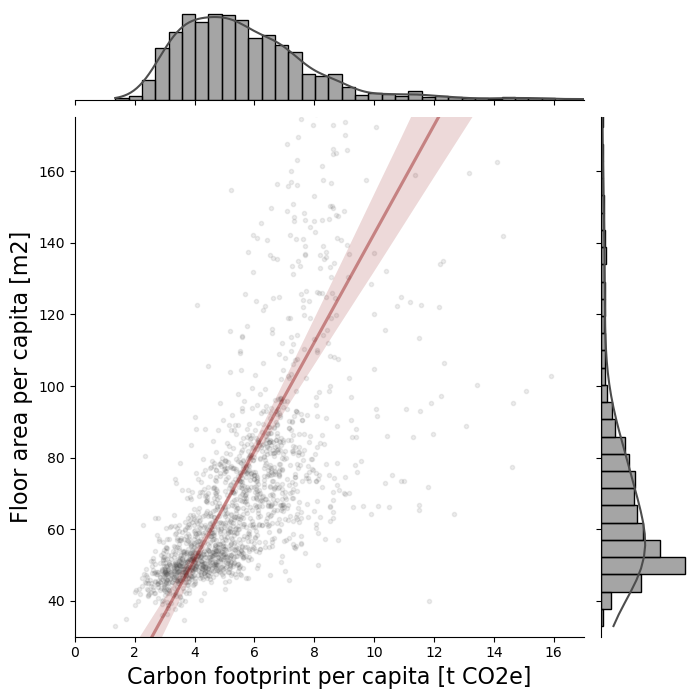

In [414]:
ghg_annual_sum = (ghg_annual.sum(1)/1000).rename('t_co2e') #t CO2e GHG emissions per household
ghg_annual_sum_m2 = pd.concat([ghg_annual_sum, use['size'+year+'_w1']], axis=1) #t CO2e GHG emissions per household AND m2 floor area per household
ghg_annual_sum_m2_cap = ghg_annual_sum_m2.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0) #both per capita

g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", data=ghg_annual_sum_m2_cap,
                  kind="reg", truncate=False,
                  marker='.',
                  scatter_kws={
                    "alpha": 0.1,
                    },
                  line_kws={
                      "color": "darkred",
                      "alpha": 0.4
                  },
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/'+class_name_short+'/scatter_ghg_m2'+year+'.png')

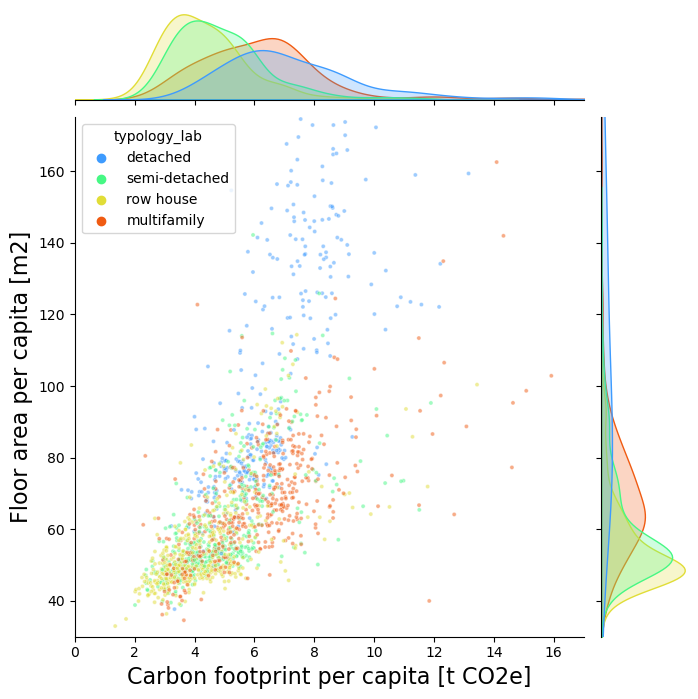

In [415]:
df = ghg_annual_sum_m2_cap.reset_index()
g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", hue='typology_lab', data=df,
                  #kind="kde", truncate=False,
                  marker='.',
                  joint_kws={"alpha": 0.5},
                  palette='turbo',
                  #line_kws={"color": "darkred","alpha": 0.4},
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/'+class_name_short+'/scatter_ghg_m2_type'+year+'.png')

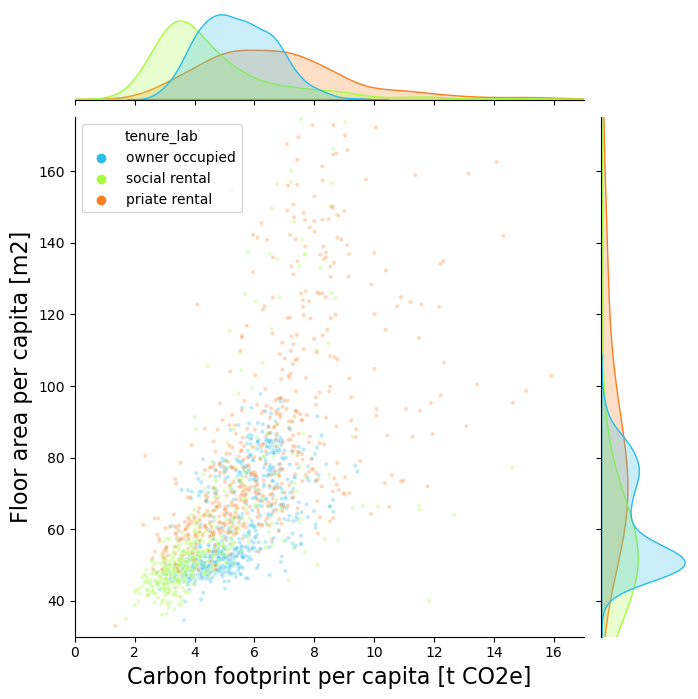

In [416]:
df = ghg_annual_sum_m2_cap.reset_index()
g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", hue=lab, data=df,
                  #kind="kde", truncate=False,
                  marker='.',
                  joint_kws={"alpha": 0.3},
                  palette='turbo',
                  #line_kws={"color": "darkred","alpha": 0.4},
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/'+class_name_short+'/scatter_ghg_m2_class'+year+'.png')

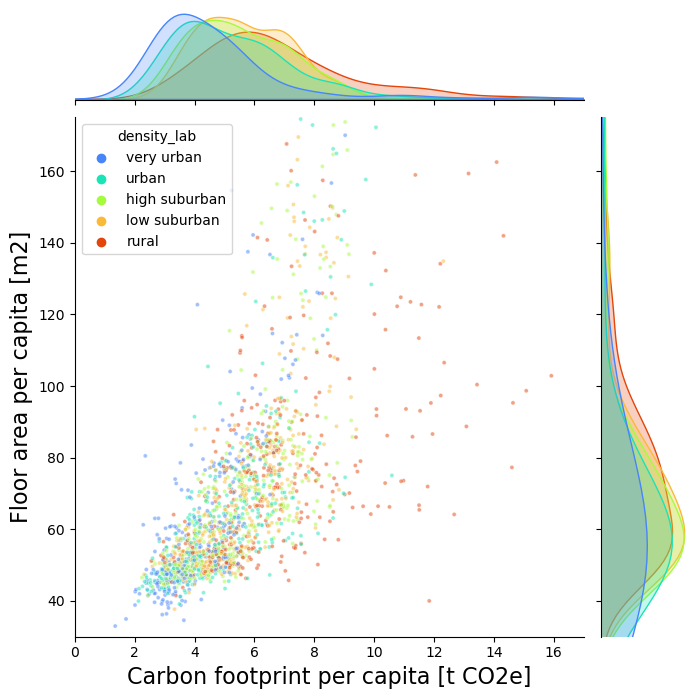

In [417]:
df = ghg_annual_sum_m2_cap.reset_index()
g = sns.jointplot(y="size"+year+"_w1", x="t_co2e", hue='density_lab', data=df,
                  #kind="kde", truncate=False,
                  marker='.',
                  joint_kws={"alpha": 0.5},
                  palette='turbo',
                  #line_kws={"color": "darkred","alpha": 0.4},
                  xlim=(0, 17), ylim=(30, 175),
                  color="0.3", 
                  height=7,
                  )
g.set_axis_labels('Carbon footprint per capita [t CO2e]', 'Floor area per capita [m2]', fontsize=16)
g.savefig('visualisations/'+class_name_short+'/scatter_ghg_m2_urb'+year+'.png')

In [418]:
    ghg_annual_size = ghg_annual.copy()
    ghg_annual_size['size_lab'] = 'medium'
    use_m2_per_cap = use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year]
    ghg_annual_size.loc[use_m2_per_cap<use_m2_per_cap.quantile(0.25), 'size_lab'] = 'smallest'
    ghg_annual_size.loc[use_m2_per_cap>use_m2_per_cap.quantile(0.75), 'size_lab'] = 'largest'
    ghg_annual_size = ghg_annual_size.assign(size_lab=ghg_annual_size['size_lab']).set_index('size_lab', append=True)
    ghg_annual_size.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    #ghg_annual_size.columns = ['Construction', 'Heating', 'Heating', 'Heating', 'Electricity', 'Electricity', 'Mobility', 'Mobility', 'Mobility']

    df = (ghg_annual_size.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)/1000).groupby(level=5, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'floor area', 'value']

    fig = px.bar(df, x='value', y='floor area',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/'+class_name_short+'/stackedbars_ghg_per_cap_process_m2'+year+'.png', scale=3)
    fig.show()

In [419]:
    ghg_annual_size = ghg_annual.copy()
    ghg_annual_size['size_lab'] = 'medium'
    use_m2_per_cap = use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year]
    ghg_annual_size.loc[use_m2_per_cap<use_m2_per_cap.quantile(0.25), 'size_lab'] = 'smallest'
    ghg_annual_size.loc[use_m2_per_cap>use_m2_per_cap.quantile(0.75), 'size_lab'] = 'largest'
    ghg_annual_size = ghg_annual_size.assign(size_lab=ghg_annual_size['size_lab']).set_index('size_lab', append=True)
    #ghg_annual_size.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    ghg_annual_size.columns = ['Construction', 'Heating', 'Heating', 'Heating', 'Electricity', 'Electricity', 'Mobility', 'Mobility', 'Mobility']
    ghg_annual_size = ghg_annual_size.groupby(level=0, axis=1, sort=False).sum()

    df = (ghg_annual_size.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)/1000).groupby(level=5, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'floor area', 'value']

    fig = px.bar(df, x='value', y='floor area',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec                               
                                        'rgb(000,114,178)', #car
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/'+class_name_short+'/stackedbars_ghg_per_cap_agg_m2'+year+'.png', scale=3)
    fig.show()

In [420]:
    ghg_annual_size = ghg_annual.copy()
    ghg_annual_size['size_lab'] = 'medium'
    use_m2_per_cap = use['size'+year+'_w1']*use['n_hhd']/use['n_hhdmem'+year]
    ghg_annual_size.loc[use_m2_per_cap<use_m2_per_cap.quantile(1/3), 'size_lab'] = 'small <'+str(int(round(use_m2_per_cap.quantile(1/3),0)+1))+'m<sup>2</sup>'
    ghg_annual_size.loc[use_m2_per_cap>use_m2_per_cap.quantile(2/3), 'size_lab'] = 'large >'+str(int(round(use_m2_per_cap.quantile(2/3),0)))+'m<sup>2</sup>'
    ghg_annual_size = ghg_annual_size.assign(size_lab=ghg_annual_size['size_lab']).set_index('size_lab', append=True)
    #ghg_annual_size.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    ghg_annual_size.columns = ['Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing', 'Housing']
    ghg_annual_size = ghg_annual_size.groupby(level=0, axis=1, sort=False).sum()

    df = (ghg_annual_size.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0)/1000).groupby(level=5, sort=False).mean().unstack().reset_index()
    df.columns = ['process', 'floor area', 'value']

    fig = px.bar(df, x='value', y='floor area',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec                               
                                        'rgb(000,114,178)', #car
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=300, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
    fig.write_image('visualisations/'+class_name_short+'/stackedbars_ghg_per_cap_total_m2'+year+'.png', scale=3)
    fig.show()

In [421]:
    ghg_annual_df = ghg_annual.copy()
    ghg_annual_df = ghg_annual_df/1000 #conversion to t co2e
    ghg_annual_df.columns = ['Building material', 'Heat pump', 'District heating', 'Gas', 'Electricity', 'PV', 'Car use', 'Transit', 'Cycling']
    #ghg_annual_df.columns = ['Construction', 'Heating', 'Heating', 'Heating', 'Electricity', 'Electricity', 'Mobility', 'Mobility', 'Mobility']
    #ghg_annual_df = ghg_annual_df.groupby(level=0, axis=1, sort=False).sum()
    df = ghg_annual_df.multiply(use['n_hhd'], axis=0).div(use['n_hhdmem'+year], axis=0).groupby(level=0, sort=False).mean().unstack().reset_index()
    df.columns = ['process', class_name, 'value']

    fig = px.bar(df, x='value', y=class_name,color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 labels={'value':'Carbon footprint of housing per capita per year [t CO<sub>2</sub>e]'}, 
                 template='simple_white', 
             color_discrete_sequence=['rgb(000,000,000)', #buildings                                       
                                        'rgb(204,121,167)', #hp
                                        'rgb(126,041,084)', #dh,
                                        'rgb(213,094,000)', #gas
                                        'rgb(230,159,000)', #elec
                                        'rgb(240,228,066)', #pv                                  
                                        'rgb(000,114,178)', #car
                                        'rgb(086,180,233)', #transit                                         
                                        'rgb(000,158,115)', #cycling
                                        ]) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)
fig.write_image('visualisations/'+class_name_short+'/stackedbars_ghg_per_cap_process_class'+year+'.png', scale=3)
fig.show()

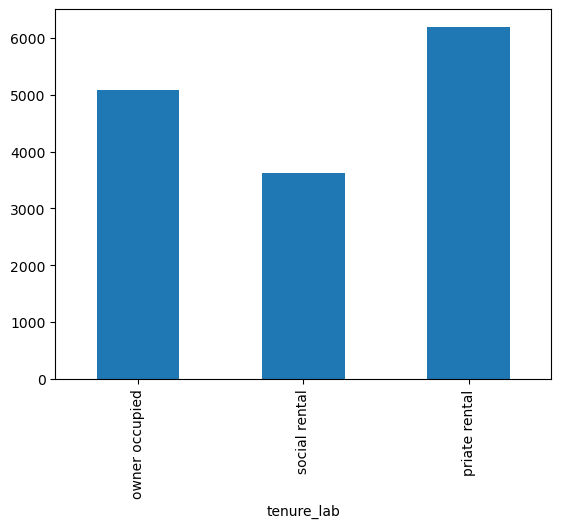

In [422]:
#floor area per income level
use_m2_total_class = (ghg_annual.sum(1)*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class = use['n_hhdmem'+year].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class #m2/cap in each income group
use_m2_per_cap_class.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and building type
use_m2_total_class_type = (ghg_annual.sum(1)*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_class_type = use['n_hhdmem'+year].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_class_type = use_m2_total_class_type / use_cap_total_class_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_class
df2=use_m2_per_cap_class_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()
df2 = df2.reset_index()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'kg CO2eq. per capita', lab:class_name_long}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))

df2=use_m2_per_cap_class_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()

for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))
fig.update_traces(marker_line_width=0)
fig.write_image('visualisations/'+class_name_short+'/bubblechart_ghg_per_cap_class_type'+year+'.png', scale=3)
fig.show()

In [423]:
#df = use[[class_col,'size'+year+'_w1', 'gas'+year, 'n_heatpump'+year,'netelectricity'+year, 'car_pkm']].reset_index()
#sns.pairplot(df, hue="typology_lab", kind="reg", plot_kws={'scatter_kws': {'alpha': 0.1}})

In [424]:
# Floor area per income level
use_m2_total_class = (ghg_annual.sum(1) * use['n_hhd']).groupby(level=0, sort=False).sum()  # Total kg CO2eq summed by income level
use_cap_total_class = use['n_hhdmem2019'].groupby(level=0, sort=False).sum()  # Total people summed by income level
use_m2_per_cap_class = use_m2_total_class / use_cap_total_class  # kg CO2eq per capita for each income level

# Floor area per income level and urbanity type (density_lab)
use_m2_total_class_type = (ghg_annual.sum(1) * use['n_hhd']).groupby(level=[0, 3], sort=False).sum()  # Group by income and urbanity
use_cap_total_class_type = use['n_hhdmem2019'].groupby(level=[0, 3], sort=False).sum()  # Total people by income and urbanity
use_m2_per_cap_class_type = use_m2_total_class_type / use_cap_total_class_type  # kg CO2eq per capita by income and urbanity

# Preparing the dataframes for plotting
df = use_m2_per_cap_class
df2 = use_m2_per_cap_class_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0, 3], sort=False).sum()
df2 = df2.reset_index()  # Reset index for easier plotting

# Define urbanity colors
urban_colors = ['#000000', '#f3722c', '#f8961e', '#90be6d', '#43aa8b']  

# Bar Chart for overall kg CO2eq per capita by income level
fig = px.bar(
    df,
    x=df.values,
    y=df.index,
    labels={'x':'kg CO2eq. per capita', lab:class_name_long}, 
    template='simple_white',
    color_discrete_sequence=urban_colors
)
fig.update_layout(
    width=1000,
    height=500,
    font=dict(size=18),
    bargap=0.9,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    )
)

# Bubble Chart Overlay for urbanity (density_lab)
for urbanity in df2['density_lab'].unique():  # Use 'density_lab' for urbanity levels
    df_plot = df2[df2['density_lab'] == urbanity]  # Filter by urbanity type
    fig.add_trace(go.Scatter(
        y=df_plot[lab],  # Income level
        x=df_plot['value'],  # kg CO2eq per capita
        mode='markers',
        name=urbanity,  # Urbanity level as legend
        marker=dict(
            size=df_plot['n_hhd'],  # Bubble size based on households
            sizemode='area',
            sizeref=4 * max(df2['n_hhd']) / (40.0**2),  # Normalize bubble size
            sizemin=4,  # Minimum bubble size
        ),
        showlegend=True
    ))

# Save and display the final plot
fig.update_traces(marker_line_width=0)
fig.write_image('visualisations/'+class_name_short+'/bubblechart_ghg_per_cap_class_urbanity.png', scale=3)
fig.show()


In [425]:
# per capita emissions
total_emissions = (ghg_annual.sum(axis=1) * use['n_hhd']).groupby(['typology_lab', 'density_lab', lab]).sum()
total_people = use.groupby(['typology_lab', 'density_lab', lab])['n_hhdmem2019'].sum()
co2_per_capita = (total_emissions / total_people).unstack(level=lab)

# Emission statistics
emission_stats_per_capita = pd.DataFrame({
    'highest_classome_emission_per_capita': co2_per_capita.max(axis=1),  
    'lowest_classome_emission_per_capita': co2_per_capita.min(axis=1),  
    'median_classome_emission_per_capita': co2_per_capita.median(axis=1),
    'mean_classome_emission_per_capita': co2_per_capita.mean(axis=1),
    'total_population': total_people.groupby(['typology_lab', 'density_lab']).sum()
}).reset_index()

# Saving results to excel
output_file = "data_input/density_housing_combo_emissions.xlsx"
emission_stats_per_capita.to_excel(output_file, index=False)

print('saved', output_file)

saved data_input/density_housing_combo_emissions.xlsx


In [426]:
# per capita emissions
total_emissions = (ghg_annual.sum(axis=1) * use['n_hhd']).groupby(['typology_lab', 'density_lab', lab]).sum()
total_people = use.groupby(['typology_lab', 'density_lab', lab])['n_hhdmem2019'].sum()
co2_per_capita = (total_emissions / total_people).unstack(level='typology_lab')

# Emission statistics
emission_stats_per_capita = pd.DataFrame({
    'highest_classome_emission_per_capita': co2_per_capita.max(axis=1),  
    'lowest_classome_emission_per_capita': co2_per_capita.min(axis=1),  
    'median_classome_emission_per_capita': co2_per_capita.median(axis=1),
    'mean_classome_emission_per_capita': co2_per_capita.mean(axis=1),
    'total_population': total_people.groupby(['density_lab', lab]).sum()
}).reset_index()

# Saving results to excel
output_file = "data_input/density_class_combo_emissions.xlsx"
emission_stats_per_capita.to_excel(output_file, index=False)

print('saved', output_file)

saved data_input/density_class_combo_emissions.xlsx


In [427]:
# per capita emissions
total_emissions = (ghg_annual.sum(axis=1) * use['n_hhd']).groupby(['typology_lab', 'density_lab', lab]).sum()
total_people = use.groupby(['typology_lab', 'density_lab', lab])['n_hhdmem2019'].sum()
co2_per_capita = (total_emissions / total_people).unstack(level='density_lab')

# Emission statistics
emission_stats_per_capita = pd.DataFrame({
    'highest_classome_emission_per_capita': co2_per_capita.max(axis=1),  
    'lowest_classome_emission_per_capita': co2_per_capita.min(axis=1),  
    'median_classome_emission_per_capita': co2_per_capita.median(axis=1),
    'mean_classome_emission_per_capita': co2_per_capita.mean(axis=1),
    'total_population': total_people.groupby(['typology_lab', lab]).sum()
}).reset_index()

# Saving results to excel
output_file = "data_input/typology_class_combo_emissions.xlsx"
emission_stats_per_capita.to_excel(output_file, index=False)

print('saved', output_file)

saved data_input/typology_class_combo_emissions.xlsx


In [428]:
co2_per_capita

density_lab                   high suburban  low suburban     rural    urban  \
typology_lab  tenure_lab                                                       
detached      owner occupied       5,828.96      5,978.63  6,377.92 5,723.08   
              priate rental        8,198.66      7,658.94 10,952.35 8,770.58   
              social rental        6,561.57      5,450.81  6,106.51 6,696.39   
multifamily   owner occupied       6,836.52      7,149.38  6,424.39 6,328.11   
              priate rental        7,133.28      7,445.98 11,944.59 6,194.92   
              social rental        4,716.77      5,434.81  6,861.83 3,830.98   
row house     owner occupied       4,476.43      4,789.75  5,280.77 4,218.70   
              priate rental        4,545.76      4,615.65  8,893.11 4,455.75   
              social rental        3,310.96      3,542.80  4,387.60 2,884.63   
semi-detached owner occupied       4,943.49      5,133.87  5,577.02 4,755.98   
              priate rental        5,441.57      5,618.64  9,490.45 5,273.85   
              social rental        3,788.37      4,013.16  4,882.45 3,340.22   

density_lab                   very urban  
typology_lab  tenure_lab                  
detached      owner occupied    5,306.28  
              priate rental    10,987.49  
              social rental     7,523.49  
multifamily   owner occupied    4,820.77  
              priate rental     5,238.97  
              social rental     3,293.03  
row house     owner occupied    3,778.16  
              priate rental     5,757.53  
              social rental     2,825.29  
semi-detached owner occupied    4,243.18  
              priate rental     6,391.93  
              social rental     3,206.56

In [429]:
# per capita emissions
co2_by_classome_housing = (ghg_annual.sum(axis=1) * use['n_hhd']).groupby([lab, 'typology_lab']).sum()
household_members = use.groupby([lab, 'typology_lab'])['n_hhdmem2019'].sum()
co2_per_capita = (co2_by_classome_housing / household_members).unstack(level='typology_lab')  # Convert housing types into columns

# Find the lowest and highest per capita emitting housing types per income group
lowest_emitting_housing_type = co2_per_capita.idxmin(axis=1)  # Housing type with the lowest per capita emissions
highest_emitting_housing_type = co2_per_capita.idxmax(axis=1)  # Housing type with the highest per capita emissions
lowest_emission_value = co2_per_capita.min(axis=1)  # Minimum per capita emissions per income group
highest_emission_value = co2_per_capita.max(axis=1)  # Maximum per capita emissions per income group

# Combining results
emission_comparison = pd.DataFrame({
    'income_group': co2_per_capita.index,
    'lowest_emitting_housing_type': lowest_emitting_housing_type,
    'lowest_emission_per_capita_kgCO2eq': lowest_emission_value,
    'highest_emitting_housing_type': highest_emitting_housing_type,
    'highest_emission_per_capita_kgCO2eq': highest_emission_value,
}).reset_index(drop=True)

# Saving as an xlsx file
output_file = "data_input/housing_type_emissions.xlsx"
emission_comparison.to_excel(output_file, index=False)

print('saved', output_file)

saved data_input/housing_type_emissions.xlsx



Results:
--------
Income Groups:
Highest (Decile owner occupied): 5,088.17 kg CO2eq
Median (Decile social rental): 3,616.58 kg CO2eq
Lower Quartile (Decile priate rental): 6,200.48 kg CO2eq
Upper Quartile (Decile owner occupied): 5,088.17 kg CO2eq

Median Decile Urbanity:
Urban: 3,416.13 kg CO2eq
Low Suburban: 4,134.89 kg CO2eq
High Suburban: 3,876.22 kg CO2eq
Very Urban: 3,201.39 kg CO2eq

Median Decile Housing Types:
Row House: 3,199.56 kg CO2eq
Semi-detached: 3,857.83 kg CO2eq
Detached: 6,182.58 kg CO2eq
Multiple Family: 3,806.56 kg CO2eq

All Combinations in Median Decile:
--------------------------------
very urban + detached: 7,523.49 kg CO2eq
urban + detached: 6,696.39 kg CO2eq
high suburban + detached: 6,561.57 kg CO2eq
low suburban + detached: 5,450.81 kg CO2eq
low suburban + multifamily: 5,434.81 kg CO2eq
high suburban + multifamily: 4,716.77 kg CO2eq
low suburban + semi-detached: 4,013.16 kg CO2eq
urban + multifamily: 3,830.98 kg CO2eq
high suburban + semi-detached: 3,788.3

TypeError: got an unexpected keyword argument 'bbox_classhes'

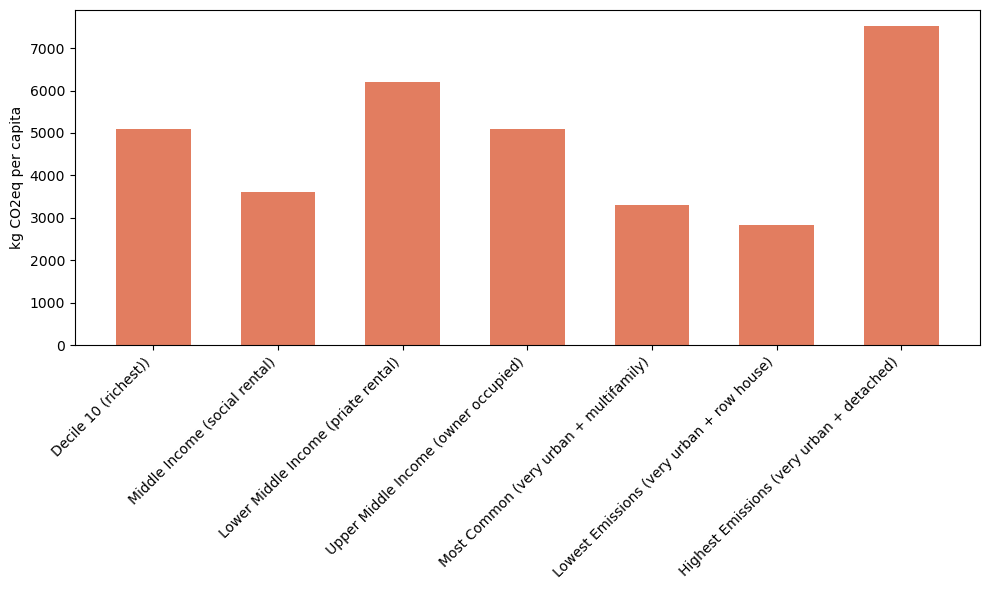

In [430]:
def analyze_emissions_distribution(ghg_annual, use):
    # Calculate total emissions for finding deciles
    total_emissions = (ghg_annual.sum(1) * use['n_hhd']).groupby(level=0, sort=False).sum()
    
    # Find deciles based on total emissions
    median_value = np.median(total_emissions)
    q1_value = np.percentile(total_emissions, 25)
    q3_value = np.percentile(total_emissions, 75)
    
    median_decile = total_emissions.index[np.abs(total_emissions - median_value).argmin()]
    q1_decile = total_emissions.index[np.abs(total_emissions - q1_value).argmin()]
    q3_decile = total_emissions.index[np.abs(total_emissions - q3_value).argmin()]
    highest_decile = total_emissions.index[np.abs(total_emissions - total_emissions.max()).argmin()]

    def calculate_mean_per_capita(ghg_annual, use, decile, category_type=None, category_value=None, second_category_type=None, second_category_value=None):
        if category_type and category_value and second_category_type and second_category_value:
            mask = (ghg_annual.index.get_level_values(lab) == decile) & \
                   (ghg_annual.index.get_level_values(category_type) == category_value) & \
                   (ghg_annual.index.get_level_values(second_category_type) == second_category_value)
        elif category_type and category_value:
            mask = (ghg_annual.index.get_level_values(lab) == decile) & \
                   (ghg_annual.index.get_level_values(category_type) == category_value)
        else:
            mask = ghg_annual.index.get_level_values(lab) == decile
    
        emissions_total = (ghg_annual[mask].sum(1) * use[mask]['n_hhd']).sum()
        population_total = (use[mask]['n_hhdmem2019']).sum()
    
        return emissions_total / population_total if population_total > 0 else 0

    # Get most common housing-urbanity combination in median decile
    group_data = use.xs(median_decile, level=0)
    combinations = group_data.groupby(['density_lab', 'typology_lab'])['n_hhd'].sum()
    most_common_combo = combinations.idxmax()
    median_urbanity, median_housing = most_common_combo
    
    # Calculate emissions for most common combination
    combo_emissions = calculate_mean_per_capita(
        ghg_annual, use, median_decile, 
        'density_lab', median_urbanity, 
        'typology_lab', median_housing
    )

    # Calculate mean per capita emissions
    highest_per_capita = calculate_mean_per_capita(ghg_annual, use, highest_decile)
    median_per_capita = calculate_mean_per_capita(ghg_annual, use, median_decile)
    q1_per_capita = calculate_mean_per_capita(ghg_annual, use, q1_decile)
    q3_per_capita = calculate_mean_per_capita(ghg_annual, use, q3_decile)

    # Calculate for urbanity types in median decile
    median_urban = calculate_mean_per_capita(ghg_annual, use, median_decile, 'density_lab', 'urban')
    median_low_suburban = calculate_mean_per_capita(ghg_annual, use, median_decile, 'density_lab', 'low suburban')
    median_high_suburban = calculate_mean_per_capita(ghg_annual, use, median_decile, 'density_lab', 'high suburban')
    median_very_urban = calculate_mean_per_capita(ghg_annual, use, median_decile, 'density_lab', 'very urban')

    # Calculate for housing types in median decile
    median_row_house = calculate_mean_per_capita(ghg_annual, use, median_decile, 'typology_lab', 'row house')
    median_semi_detached = calculate_mean_per_capita(ghg_annual, use, median_decile, 'typology_lab', 'semi-detached')
    median_detached = calculate_mean_per_capita(ghg_annual, use, median_decile, 'typology_lab', 'detached')
    median_multi_fam = calculate_mean_per_capita(ghg_annual, use, median_decile, 'typology_lab', 'multifamily')

    # Calculate all combinations for median decile
    urbanity_types = ['urban', 'low suburban', 'high suburban', 'very urban']
    housing_types = ['row house', 'semi-detached', 'detached', 'multifamily']
    
    all_combinations = {}
    for urbanity in urbanity_types:
        for housing in housing_types:
            combo_key = f"{urbanity} + {housing}"
            all_combinations[combo_key] = calculate_mean_per_capita(
                ghg_annual, use, median_decile,
                'density_lab', urbanity,
                'typology_lab', housing
            )

    print(f"""
Results:
--------
Income Groups:
Highest (Decile {highest_decile}): {float(highest_per_capita):,.2f} kg CO2eq
Median (Decile {median_decile}): {float(median_per_capita):,.2f} kg CO2eq
Lower Quartile (Decile {q1_decile}): {float(q1_per_capita):,.2f} kg CO2eq
Upper Quartile (Decile {q3_decile}): {float(q3_per_capita):,.2f} kg CO2eq

Median Decile Urbanity:
Urban: {float(median_urban):,.2f} kg CO2eq
Low Suburban: {float(median_low_suburban):,.2f} kg CO2eq
High Suburban: {float(median_high_suburban):,.2f} kg CO2eq
Very Urban: {float(median_very_urban):,.2f} kg CO2eq

Median Decile Housing Types:
Row House: {float(median_row_house):,.2f} kg CO2eq
Semi-detached: {float(median_semi_detached):,.2f} kg CO2eq
Detached: {float(median_detached):,.2f} kg CO2eq
Multiple Family: {float(median_multi_fam):,.2f} kg CO2eq

All Combinations in Median Decile:
--------------------------------""")
    
    # Print all combinations sorted by emissions
    sorted_combinations = dict(sorted(all_combinations.items(), key=lambda x: x[1], reverse=True))
    for combo, emissions in sorted_combinations.items():
        print(f"{combo}: {float(emissions):,.2f} kg CO2eq")

    print(f"""
Most Common Housing-Urbanity Combination in Median Decile:
{median_urbanity} + {median_housing}
Number of households: {combinations[most_common_combo]:,.0f}
Per capita emissions: {float(combo_emissions):,.2f} kg CO2eq
""")

    # Get min and max emission combinations
    min_combo = min(all_combinations.items(), key=lambda x: x[1])
    max_combo = max(all_combinations.items(), key=lambda x: x[1])

    # Prepare plot data in specified order
    plot_data = {
        f'Decile 10 (richest))': float(highest_per_capita),
        f'Middle Income ({median_decile})': float(median_per_capita),
        f'Lower Middle Income ({q1_decile})': float(q1_per_capita),
        f'Upper Middle Income ({q3_decile})': float(q3_per_capita),
        f'Most Common ({median_urbanity} + {median_housing})': float(combo_emissions),
        f'Lowest Emissions ({min_combo[0]})': float(min_combo[1]),
        f'Highest Emissions ({max_combo[0]})': float(max_combo[1])
    }

    plot_data_2 = {
        f'Decile 10 (richest))': float(highest_per_capita),
        f'Middle Income ({median_decile})': float(median_per_capita),
        f'Lower Middle Income ({q1_decile})': float(q1_per_capita),
        f'Upper Middle Income ({q3_decile})': float(q3_per_capita),
        f'Urban ({median_decile})': float(median_urban),
        f'Low Suburban ({median_decile})': float(median_low_suburban),
        f'Row House ({median_decile})': float(median_row_house),
        f'Semi-detached ({median_decile})': float(median_semi_detached)
    }
    # Create first plot
    plt.figure(figsize=(10, 6))
    bars = plt.bar(plot_data.keys(), plot_data.values(), color='#E27D60', width=0.6)
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('kg CO2eq per capita')
    plt.tight_layout()
    plt.savefig('visualisations/'+class_name_short+'/emissions_distribution.png', dpi=300, bbox_classhes='tight')
    plt.show()

    # Create second plot
    plt.figure(figsize=(10, 6))
    bars = plt.bar(plot_data_2.keys(), plot_data_2.values(), color='#E27D60', width=0.6)
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('kg CO2eq per capita')
    plt.tight_layout()
    plt.savefig('visualisations/'+class_name_short+'/emissions_comparison.png', dpi=300, bbox_classhes='tight')
    plt.show()

    # Create second plot with all combinations
    plt.figure(figsize=(15, 8))
    bars = plt.bar(sorted_combinations.keys(), sorted_combinations.values(), color='#E27D60')
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('kg CO2eq per capita')
    plt.tight_layout()
    plt.savefig('visualisations/'+class_name_short+'/emissions_combinations.png', dpi=300, bbox_classhes='tight')
    plt.show()

analyze_emissions_distribution(ghg_annual, use)

In [ ]:
income_order = ['decile 1 (poorest)', 'decile 2', 'decile 3', 'decile 4', 'decile 5',
                'decile 6', 'decile 7', 'decile 8', 'decile 9', 'decile 10 (richest)']

ownership_summary = use.groupby([lab]).agg(
    total_households=('n_hhd', 'sum'),
    pv_owners=('n_solar2019', 'sum'),
    heat_pump_owners=('n_heatpump2019', 'sum'),
    distance_train=('distance_train2019', lambda x: (x * use.loc[x.index, 'n_hhd']).sum() / (use.loc[x.index, 'n_hhdmem2019']).sum()) #per capita 
    #distance_train=('distance_train2019', lambda x: (x * use.loc[x.index, 'n_hhd']).sum() / use.loc[x.index, 'n_hhd'].sum()) #per household
).reset_index()

ownership_summary[lab] = pd.Categorical(ownership_summary[lab],
                                            categories=income_order,
                                            ordered=True)
ownership_summary = ownership_summary.sort_values(lab)

# Heat Pump Plot
heat_pump_summary = ownership_summary.groupby(lab)['heat_pump_owners'].sum()
fig1 = go.Figure()
fig1.add_trace(
    go.Bar(y= heat_pump_summary.values,
           x= heat_pump_summary.index,
           orientation='v')
)
fig1.update_layout(
    height=500,
    width=600,
    font=dict(size=16),
    xaxis_title=class_name ,
    yaxis_title='Households with Heat Pumps',
    template='simple_white',
    margin=dict(t=20)
)
fig1.write_image('visualisations/'+class_name_short+'/heat_pump_analysis.png', scale=2)
fig1.show()

# PV Plot
pv_summary = ownership_summary.groupby(lab)['pv_owners'].sum()
fig2 = go.Figure()
fig2.add_trace(
    go.Bar(y= pv_summary.values,
           x= pv_summary.index,
           orientation='v')
)
fig2.update_layout(
    height=500,
    width=600,
    font=dict(size=16),
    xaxis_title=class_name ,
    yaxis_title='Households with Solar Panels',
    template='simple_white',
    margin=dict(t=20)
)

fig2.write_image('visualisations/'+class_name_short+'/pv_analysis.png', scale=2)
fig2.show()

# Train distance plot
train_summary = ownership_summary.groupby(lab)['distance_train'].sum()
fig3 = go.Figure()
fig3.add_trace(
    go.Bar(y=train_summary.values,
           x=train_summary.index,
           orientation='v')
)
fig3.update_layout(
    height=500,
    width=600,
    font=dict(size=16),
    xaxis_title=class_name,
    yaxis_title='Mean distance to train station [m]',
    template='simple_white',
    margin=dict(t=20)
)
fig3.write_image('visualisations/'+class_name_short+'/train_distance_analysis.png', scale=2)
fig3.show()

### Statistical analysis

In [ ]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Load data
dat = sm.datasets.get_rdataset("Guerry", "HistData").data
# Fit regression model (using the natural log of one of the regressors)
results = smf.ols('Lottery ~ Literacy + np.log(Pop1831)', data=dat).fit()


In [ ]:
correlates = pd.DataFrame()

                            OLS Regression Results                            
Dep. Variable:                 kg_ghg   R-squared:                       0.355
Model:                            OLS   Adj. R-squared:                  0.355
Method:                 Least Squares   F-statistic:                     645.9
Date:                Thu, 13 Mar 2025   Prob (F-statistic):               0.00
Time:                        17:09:16   Log-Likelihood:                -50471.
No. Observations:                5872   AIC:                         1.010e+05
Df Residuals:                    5866   BIC:                         1.010e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             2812.2138 

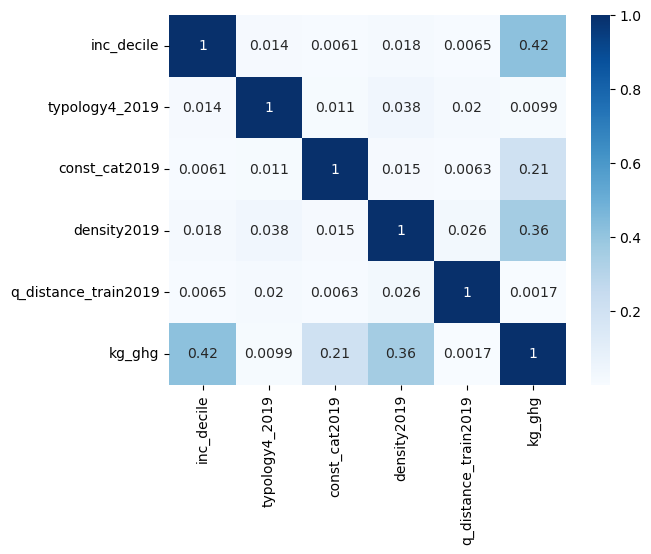

In [ ]:
ghg_annual_per_cap_iloc = ghg_annual_per_cap.join(use.loc[:,:'q_distance_train2019']).set_index([class_col, 'typology4_2019', 'const_cat2019', 'density2019',
       'q_distance_train2019'])
dat = ghg_annual_per_cap_iloc.sum(1).rename('kg_ghg').reset_index()
dat = dat[dat['kg_ghg']!=0]

results = smf.ols('kg_ghg ~ '+class_col+' + typology4_2019 + const_cat2019 + density2019 + q_distance_train2019', data=dat).fit()
print(results.summary())

results = smf.ols('kg_ghg ~ '+class_col+'', data=dat).fit()
print(class_name_short, results.summary())

results = smf.ols('kg_ghg ~ typology4_2019 + const_cat2019', data=dat).fit()
print('building', results.summary())

results = smf.ols('kg_ghg ~ density2019', data=dat).fit()
print('location', results.summary())

sns.heatmap(dat.corr().abs(), cmap="Blues", annot=True)
correlates['total'] = dat.corr().abs()['kg_ghg']

                            OLS Regression Results                            
Dep. Variable:                 kg_ghg   R-squared:                       0.415
Model:                            OLS   Adj. R-squared:                  0.414
Method:                 Least Squares   F-statistic:                     821.8
Date:                Thu, 13 Mar 2025   Prob (F-statistic):               0.00
Time:                        17:09:20   Log-Likelihood:                -48797.
No. Observations:                5800   AIC:                         9.761e+04
Df Residuals:                    5794   BIC:                         9.765e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             -731.6275 

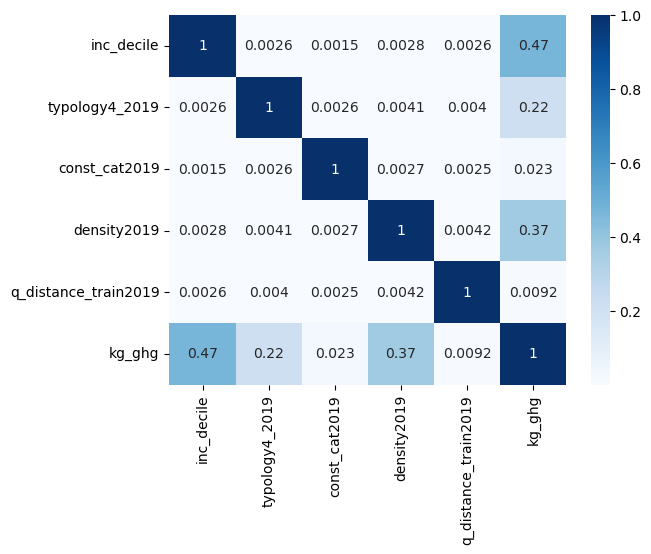

In [ ]:
ghg_annual_per_cap_iloc = ghg_annual_per_cap.join(use.loc[:,:'q_distance_train2019']).set_index([class_col, 'typology4_2019', 'const_cat2019', 'density2019',
       'q_distance_train2019'])
dat = ghg_annual_per_cap_iloc['ghg_car_mobilityuse'].rename('kg_ghg').reset_index()
dat = dat[dat['kg_ghg']!=0]

results = smf.ols('kg_ghg ~ '+class_col+' + typology4_2019 + const_cat2019 + density2019 + q_distance_train2019', data=dat).fit()
print(results.summary())

results = smf.ols('kg_ghg ~ '+class_col+'', data=dat).fit()
print(class_name_short, results.summary())

results = smf.ols('kg_ghg ~ typology4_2019 + const_cat2019', data=dat).fit()
print('building', results.summary())

results = smf.ols('kg_ghg ~ density2019', data=dat).fit()
print('location', results.summary())

sns.heatmap(dat.corr().abs(), cmap="Blues", annot=True)
correlates['car use'] = dat.corr().abs()['kg_ghg']

                            OLS Regression Results                            
Dep. Variable:                 kg_ghg   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     718.1
Date:                Thu, 13 Mar 2025   Prob (F-statistic):               0.00
Time:                        17:09:24   Log-Likelihood:                -36474.
No. Observations:                5872   AIC:                         7.296e+04
Df Residuals:                    5866   BIC:                         7.300e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              694.1292 

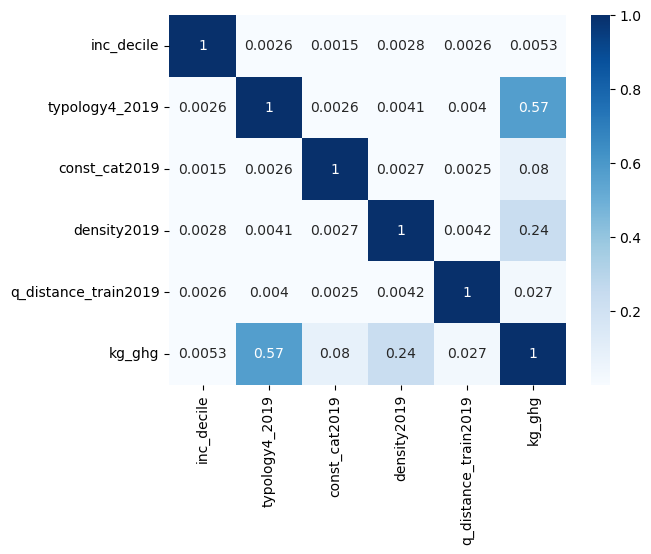

In [ ]:
ghg_annual_per_cap_iloc = ghg_annual_per_cap.join(use.loc[:,:'q_distance_train2019']).set_index([class_col, 'typology4_2019', 'const_cat2019', 'density2019',
       'q_distance_train2019'])
dat = ghg_annual_per_cap_iloc['ghg_material_buildings'].rename('kg_ghg').reset_index()
dat = dat[dat['kg_ghg']!=0]

results = smf.ols('kg_ghg ~ '+class_col+' + typology4_2019 + const_cat2019 + density2019 + q_distance_train2019', data=dat).fit()
print(results.summary())

results = smf.ols('kg_ghg ~ '+class_col+'', data=dat).fit()
print(class_name_short, results.summary())

results = smf.ols('kg_ghg ~ typology4_2019 + const_cat2019', data=dat).fit()
print('building', results.summary())

results = smf.ols('kg_ghg ~ density2019', data=dat).fit()
print('location', results.summary())

sns.heatmap(dat.corr().abs(), cmap="Blues", annot=True)
correlates['construction'] = dat.corr().abs()['kg_ghg']

                            OLS Regression Results                            
Dep. Variable:                 kg_ghg   R-squared:                       0.543
Model:                            OLS   Adj. R-squared:                  0.542
Method:                 Least Squares   F-statistic:                     1392.
Date:                Thu, 13 Mar 2025   Prob (F-statistic):               0.00
Time:                        17:09:29   Log-Likelihood:                -42776.
No. Observations:                5872   AIC:                         8.556e+04
Df Residuals:                    5866   BIC:                         8.560e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             2845.6602 

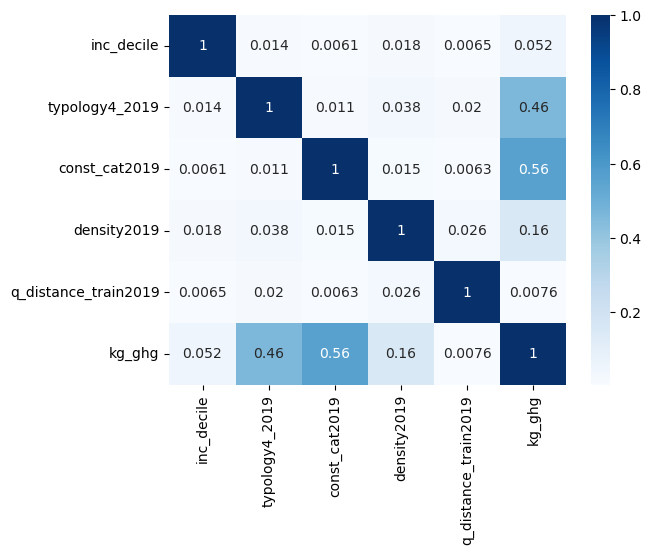

In [ ]:
ghg_annual_per_cap_iloc = ghg_annual_per_cap.join(use.loc[:,:'q_distance_train2019']).set_index([class_col, 'typology4_2019', 'const_cat2019', 'density2019',
       'q_distance_train2019'])
dat = ghg_annual_per_cap_iloc[['ghg_heat_districtheating', 'ghg_gas_buildinguse',
       'ghg_electricity_buildinguse', 'ghg_material_photovoltaic',]].sum(1).rename('kg_ghg').reset_index()
dat = dat[dat['kg_ghg']!=0]

results = smf.ols('kg_ghg ~ '+class_col+' + typology4_2019 + const_cat2019 + density2019 + q_distance_train2019', data=dat).fit()
print(results.summary())

results = smf.ols('kg_ghg ~ '+class_col+'', data=dat).fit()
print(class_name_short, results.summary())

results = smf.ols('kg_ghg ~ typology4_2019 + const_cat2019', data=dat).fit()
print('building', results.summary())

results = smf.ols('kg_ghg ~ density2019', data=dat).fit()
print('location', results.summary())

sns.heatmap(dat.corr().abs(), cmap="Blues", annot=True)
correlates['energy'] = dat.corr().abs()['kg_ghg']

In [ ]:
correlates.index = [class_name_short, 'building type', 'building age', 'density', 'train access', 'ghg']
correlates.drop('ghg', inplace=True)


TypeError: got an unexpected keyword argument 'bbox_classhes'

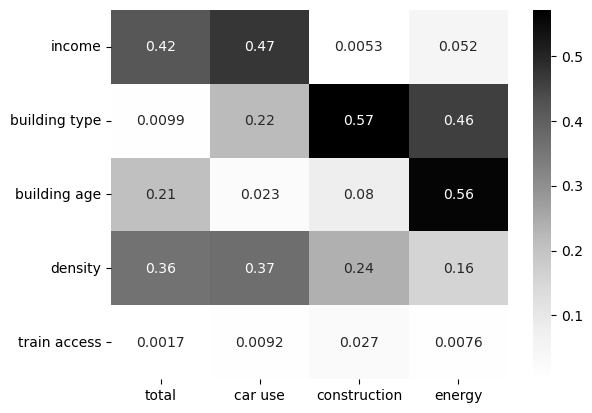

In [ ]:

sns.heatmap(correlates, cmap="Greys", annot=True)
plt.savefig('visualisations/'+class_name_short+'/heatmap_correlation.png', dpi=300, bbox_classhes='tight')

# CODE ARCHIVE

In [ ]:
# Configurations
mi_buildings_source = "Oorschot"  # Oorschot or Yang
# Load data
if mi_buildings_source == "Oorschot":
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="MI_2018",
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.name = "Material"

    mi_buildings_2018 = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="MI_2018-2050",
        index_col=[0],
        header=[0, 1],
        skipfooter=20,
    ).droplevel(1, axis=1)
    mi_buildings_2018["Cohort"] = "2018"
    mi_buildings_2018.reset_index(inplace=True)
    mi_buildings_2018["index"] = [i.lower() for i in mi_buildings_2018["index"]]
    mi_buildings_2018.set_index(["index", "Cohort"], inplace=True)
    mi_buildings_2018.index.names = ["Building type", "Cohort"]
    mi_buildings_2018.columns.name = "Material"

    mi_buildings_insulation_share = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="Share_of_insulation_materials",
        index_col=[0, 1],
        header=[0],
        skipfooter=3,
    ).drop("Unnamed: 8", axis=1)
    for i in mi_buildings_insulation_share.columns:
        mi_buildings[i] = (
            mi_buildings["Insulation"] * mi_buildings_insulation_share[i].iloc[0]
        )
        mi_buildings_2018[i] = (
            mi_buildings_2018["Insulation"] * mi_buildings_insulation_share[i].iloc[1]
        )

    mi_buildings = (
        pd.concat([mi_buildings, mi_buildings_2018], axis=1)
        .T.groupby(level=0)
        .sum()
        .T.sort_index()
        .replace(0, np.nan)
        .dropna(how="all", axis=1)
        .drop("Insulation", axis=1)
    )

# matching material names
replacement_map = {'Bitumen':'Bitumen', #soon
                    'Brick':'Ceramics', #BRIK,
                    'Clay brick':'Ceramics', #BRIK
                    'Ceramics':'Ceramics', #BRIK (bricks, tiles, construction products)
                    'Sand-lime brick':'Ceramics', #BRIK
                    'Sand':'Sand', #SDCL
                    'Concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                    'Mortal':'Mortar', #CMNT
                    'Gypsum':'Mortar', #CMNT (plaster of gypsum)
                    'Aluminum':'Aluminium', #ALUM
                    'Copper':'Copper', #COPP
                    'Other metals':'Other metals', #ONFM
                    'Electronics':'Electronics', #ELMA
                    'Glass':'Glass', #GLAS 
                    'Glass wool':'Glass', #GLAS (includes explicitely glass wool)
                    'Stone wool':'Mineral wool', #ONMM (includes explicitely mineral wool)
                    'Iron & steel':'Steel', #STEL or FABM
                    'Steel':'Steel', #STEL or FABM
                    'Other biobased materials':'Wood and straw', #WOOD
                    'Wood':'Wood and straw', #WOOD
                    'Other construction materials':'Other construction material', #ONMM, could also be STON, SDCL or CMNT
                    'Other':'Adhesives and paint', #could be CHEM, PLAS, PAPE, ELMA
                    'Paper':'Paper', #PAPE 
                    'Expanded polystyrene':'Plastic', #RUBP 
                    'Extruded polystyrene':'Plastic', #RUBP
                    'Plastic':'Plastic', #RUBP
                    'Plastics':'Plastic', #RUBP
                    'Polyurethanes':'Plastic', #RUBP
                    'Adhesives & paint':'Adhesives and paint', #CHEM (other chemical products, for glues) or PLAS (basic plastics) 
                    'Stone':'Stone', #STON
                    }

mi_buildings = mi_buildings.stack().reset_index()
mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
mi_buildings.replace('<1945','1944', inplace=True)
mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Cohort', 'Material_group']).sum().unstack().droplevel(0, axis=1)

#selecting only residential buildings
mi_buildings.drop(['industry', 'office', 'services', 'shop'], axis=0, level=0, inplace=True)

TypeError: can't multiply sequence by non-int of type 'float'

In [ ]:
# Configurations
ei_heating_source = "TABULA"  # Oorschot or Yang
# Load data
if ei_heating_source == "TABULA":
    ei_heating = pd.read_excel(
        "data_input/EI_Heating_HotWater_TABULA2017.xlsx",
        sheet_name="0_EnergyDemandIntensity",
        index_col=[0],
        header=[0],
    ).drop('Default Heating & Hot Water', axis=1)

In [ ]:
m_plot = ei_heating.copy()

m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'function', 'value']
fig = px.bar(m_plot, x='value', y='building', color='function', labels={'value':'energy intensity per floor area [kWh/m2]'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=500, height=1200, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/'+class_name_short+'/ei_heating'+ei_heating_source+'.svg')
fig.show()

In [ ]:
# Configurations
mi_buildings_source = "Yang"  # Oorschot or Yang
# Load data
if mi_buildings_source == "Yang":
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Yang2022.xlsx",
        sheet_name='0_MaterialIntensity',
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(0, axis=0).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type"]
    mi_buildings.columns.name = "Material"

    # matching material names
    replacement_map = {'bitumen adhesive compound, hot':'Bitumen', #soon
                        'clay brick':'Ceramics', #BRIK
                        'ceramic tile':'Ceramics', #BRIK (bricks, tiles, construction products)
                        'sand':'Sand', #SDCL
                        'concrete, normal':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'fibre-reinforced concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'cement mortar':'Mortar', #CMNT
                        'gypsum, mineral':'Mortar', #CMNT (plaster of gypsum)
                        'aluminium, wrought alloy':'Aluminium', #ALUM ##
                        'copper':'Copper', #COPP
                        'zinc':'Zinc', #LZNC
                        'flat glass, coated':'Glass', #GLAS 
                        'glass wool mat':'Glass', #GLAS (includes explicitely glass wool)
                        'cast iron':'Steel', #STEL or FABM
                        'wire drawing, steel':'Steel', #STEL or FABM
                        'plywood, for indoor use':'Wood and straw', #WOOD
                        'sawnwood, hardwood, raw':'Wood and straw', #WOOD
                        'sawnwood, softwood, raw':'Wood and straw', #WOOD
                        'fibreboard, soft':'Wood and straw', #WOOD
                        'polystyrene, expandable':'Plastic', #RUBP 
                        'polystyrene, extruded':'Plastic', #RUBP
                        'extrusion, plastic pipes':'Plastic', #RUBP
                        'polyurethane, flexible foam':'Plastic', #RUBP
                        'gravel, crushed':'Stone', #STON
                        'argon, liquid':'Argon', #CHEM
                        }

    mi_buildings = mi_buildings.stack().reset_index()
    mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
    mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Material_group']).sum().unstack().droplevel(0, axis=1)

    nzeb = mi_buildings.loc[(mi_buildings.index.str.contains('_NZEB')) & ~(mi_buildings.index.str.contains('new'))]
    nzeb.index = [i[:-5] for i in nzeb.index]
    nzeb = nzeb + mi_buildings.loc[~(mi_buildings.index.str.contains('_NZEB')) & ~(mi_buildings.index.str.contains('new'))]
    nzeb.index = [i+'_NZEB' for i in nzeb.index]
    mi_buildings.update(nzeb)

In [ ]:
m_plot = mi_buildings[~mi_buildings.duplicated()]
m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'material', 'value']
fig = px.bar(m_plot, x='value', y='building', color='material', labels={'value':'material intensity per floor area [kg/m2]', 'sector':'Input sector'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=1100, height=700, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/'+class_name_short+'/mi_buildings'+mi_buildings_source+'.svg')
fig.show()